<a href="https://colab.research.google.com/github/Ruturaj2316/vizwiz-unanswerable-fusion/blob/main/Project__Part_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flagging unanswerable visual questions with image-text fusion

**Data:** VizWiz-VQA (Gurari et al. 2018), Creative Commons Attribution 4.0, downloaded from the official site. Photos and questions are not redistributed; clear the outputs before sharing this notebook.

## 1. Setup

One `CONFIG` dictionary holds every setting, so a run is fully described by it; its hash is stored with every trained model.

In [ ]:
import os, sys, json, time, math, random, re, shutil, hashlib, platform, warnings, subprocess
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import textwrap

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

CONFIG = {
    "seed": 0,                        # primary seed: CIs, significance tests and figures
    "seeds": [0, 1, 2],               # every trainable model is trained with each seed
    # storage: images on the fast local disk (wiped at session end); features, runs and results on Drive
    "use_drive": True,
    "out_dir": "/content/drive/MyDrive/vizwiz_individual",
    "local_out_dir": "/content/vizwiz_individual",
    "data_dir": "/content/data/vizwiz",
    "base_url": "https://vizwiz.cs.colorado.edu/VizWiz_final",
    "image_zips": ["train", "val", "test"],
    "dev_fraction": 0.10,
    "clip_model": "openai/clip-vit-base-patch16",
    "image_size": 224,
    "patch_grid": 7,                  # 14 x 14 ViT patches average-pooled to 7 x 7 regions
    "max_q_tokens": 32,               # question tokens kept for cross-attention
    "quality_size": 256,              # longest side used for the handcrafted image-quality measures
    "extract_batch_size": 64,
    "num_workers": 2,
    "n_explore_images": 1500,         # training photos sampled for the image exploration
    # training (AdamW, linear warm-up then cosine decay, early stopping on dev AUPRC)
    "train": {"epochs": 25, "batch_size": 256, "lr": 1e-3, "weight_decay": 0.01, "patience": 4,
              "warmup_epochs": 1, "grad_clip": 1.0, "train_probe": 4000},
    "models": {
        "question_only":   {"hidden": 256, "dropout": 0.3},
        "image_only":      {"hidden": 256, "dropout": 0.3},
        "early":           {"hidden": 512, "dropout": 0.3},
        "cross_attention": {"d_model": 256, "heads": 4, "layers": 2, "dropout": 0.1, "lr": 3e-4},
        "gated":           {"hidden": 256, "dropout": 0.3, "modality_dropout": 0.15},
    },
    # evaluation
    "n_bootstrap": 1000,
    "latency_budget_ms": 100,
    "target_recall_unanswerable": 0.90,   # operating point offered for deployment
}
CONFIG_HASH = hashlib.md5(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:10]
print("Config hash:", CONFIG_HASH)

Config hash: 0bdc508768


In [ ]:
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])
IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
if CONFIG["use_drive"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT = Path(CONFIG["out_dir"])
    except ImportError:
        OUT = Path(CONFIG["local_out_dir"])
else:
    OUT = Path(CONFIG["local_out_dir"])
DATA = Path(CONFIG["data_dir"])
FEAT_DIR, RUN_DIR, FIG_DIR, TAB_DIR = OUT / "features", OUT / "runs", OUT / "figures", OUT / "tables"
for d in (DATA, FEAT_DIR, RUN_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "torch": torch.__version__, "device": DEVICE}
if DEVICE == "cuda":
    ENV["gpu"] = torch.cuda.get_device_name(0)
else:
    print("No GPU: use Runtime > Change runtime type > T4 GPU (CPU works but feature extraction is slow).")

def autocast():
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda"))

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "axes.titleweight": "bold", "legend.frameon": False})
print("Outputs ->", OUT, "| device:", DEVICE)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/vizwiz_individual | device: cuda


## 2. Download the data

VizWiz-VQA is downloaded from the official site: the annotations and the train, validation and test image archives. Each archive is streamed to disk resuming a broken download where the server allows it, unzipped and deleted; a marker file makes the step skip on later runs. Sizes and times are logged for the feasibility record.

In [ ]:
import requests
from tqdm.auto import tqdm

ARCHIVES = {"Annotations.zip": f"{CONFIG['base_url']}/vqa_data/Annotations.zip",
            **{f"{s}.zip": f"{CONFIG['base_url']}/images/{s}.zip" for s in CONFIG["image_zips"]}}
DOWNLOAD_LOG = OUT / "download_log.json"


def fetch(url, dest, chunk=1 << 23):
    """Stream url to dest; resume from a partial file when the server supports byte ranges."""
    have = dest.stat().st_size if dest.exists() else 0
    headers = {"Range": f"bytes={have}-"} if have else {}
    with requests.get(url, stream=True, headers=headers, timeout=60) as r:
        if have and r.status_code != 206:
            have = 0                                   # range ignored- start again
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) + have
        with open(dest, "ab" if have else "wb") as f, tqdm(total=total, initial=have, unit="B",
                                                           unit_scale=True, desc=dest.name) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))


def fetch_and_unzip(name, url):
    done = DATA / f".{name}.done"
    if done.exists():
        print(f"{name}: already present")
        return
    free_gb = shutil.disk_usage(DATA).free / 1e9
    print(f"{name}: {free_gb:.0f} GB free on the Colab disk")
    zpath, t0 = DATA / name, time.time()
    fetch(url, zpath)
    size, t1 = zpath.stat().st_size / 1e9, time.time()
    subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(DATA)], check=True)
    zpath.unlink()
    done.touch()
    log = json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else {}
    log[name] = {"size_gb": round(size, 2), "download_min": round((t1 - t0) / 60, 1),
                 "unzip_min": round((time.time() - t1) / 60, 1)}
    DOWNLOAD_LOG.write_text(json.dumps(log, indent=2))


for name, url in ARCHIVES.items():
    fetch_and_unzip(name, url)

Annotations.zip: 253 GB free on the Colab disk


Annotations.zip:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

train.zip: 253 GB free on the Colab disk


train.zip:   0%|          | 0.00/11.3G [00:00<?, ?B/s]

val.zip: 242 GB free on the Colab disk


val.zip:   0%|          | 0.00/3.49G [00:00<?, ?B/s]

test.zip: 238 GB free on the Colab disk


test.zip:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

## 3. Annotations, labels and splits

Each record holds an image file name, the question, ten crowd answers, an answer type and the `answerable` flag; the label is `y = 1 - answerable`. Two extra columns are kept **for analysis only, never as model inputs**: `unans_votes` (how many of the ten crowd workers said the question was unanswerable or the image unsuitable) and `answer_type` (which is "unanswerable" exactly when y = 1, so it would leak the label).

**Splits.** If the official test annotations contain the `answerable` flag, the official partition is used: train -> train, validation -> dev (all tuning), test -> test. Otherwise a stratified 10% of official train becomes dev and the official validation split becomes test. The choice is printed below.

In [ ]:
UNANSWERABLE_ANSWERS = {"unanswerable", "unsuitable", "unsuitable image"}


def find_file(root, name):
    hits = sorted(p for p in root.rglob(name) if "__MACOSX" not in p.parts)
    return hits[0] if hits else None


def read_annotations(path, split):
    records = json.loads(Path(path).read_text())
    rows = []
    for r in records:
        answers = [str(a.get("answer", "")).strip().lower() for a in r.get("answers", []) or []]
        rows.append({"image": r["image"], "question": " ".join(str(r.get("question", "")).split()),
                     "answers": answers, "answer_type": r.get("answer_type"),
                     "answerable": r.get("answerable"), "official_split": split})
    return pd.DataFrame(rows)


ann = {s: find_file(DATA, f"{s}.json") for s in ("train", "val", "test")}
frames = [read_annotations(p, s) for s, p in ann.items() if p is not None]
raw = pd.concat(frames, ignore_index=True)
TEST_LABELLED = ann["test"] is not None and raw.loc[raw.official_split == "test", "answerable"].notna().all()
raw = raw[raw["answerable"].notna()].copy()            # unlabelled rows cannot be used
raw["y"] = 1 - raw["answerable"].astype(int)
raw["unans_votes"] = raw["answers"].apply(lambda a: sum(x in UNANSWERABLE_ANSWERS for x in a))
raw["consensus"] = raw["answers"].apply(lambda a: Counter(a).most_common(1)[0][1] / len(a) if a else np.nan)

# image files on disk (file name -> path)
paths = {}
for dirpath, _, files in os.walk(DATA):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and "__MACOSX" not in dirpath:
            paths[f] = os.path.join(dirpath, f)
raw["path"] = raw["image"].map(paths)
missing_img = int(raw["path"].isna().sum())
empty_q = int((raw["question"].str.len() == 0).sum())
raw = raw.dropna(subset=["path"])
raw = raw[raw["question"].str.len() > 0]

if TEST_LABELLED:
    SPLIT_SCHEME = "official train / validation (dev) / test"
    raw["split"] = raw["official_split"].map({"train": "train", "val": "dev", "test": "test"})
else:
    from sklearn.model_selection import train_test_split
    SPLIT_SCHEME = "90% of official train / 10% of official train (dev) / official validation (test)"
    tr = raw[raw.official_split == "train"]
    _, dev_rows = train_test_split(tr, test_size=CONFIG["dev_fraction"], stratify=tr["y"],
                                   random_state=CONFIG["seed"])
    raw["split"] = np.where(raw.official_split == "val", "test",
                            np.where(raw.index.isin(dev_rows.index), "dev", "train"))
    raw = raw[raw.official_split != "test"]
meta = raw.sort_values(["split", "image"], key=lambda c: c.map({"train": 0, "dev": 1, "test": 2})
                       if c.name == "split" else c).reset_index(drop=True)
assert meta["image"].is_unique, "duplicate image file names"
IDX = {s: np.where(meta["split"].values == s)[0] for s in ("train", "dev", "test")}
Y = meta["y"].values.astype(np.float32)

print("Split scheme:", SPLIT_SCHEME)
print(f"Dropped: {missing_img} records without an image file, {empty_q} with an empty question")
split_table = meta.groupby("split").agg(pairs=("y", "size"), unanswerable_rate=("y", "mean")).reindex(
    ["train", "dev", "test"]).round(3)
display(split_table)
split_table.to_csv(TAB_DIR / "splits.csv")

Split scheme: 90% of official train / 10% of official train (dev) / official validation (test)
Dropped: 0 records without an image file, 0 with an empty question


,pairs,unanswerable_rate
split,,
train,18470,0.270
dev,2053,0.269
test,4319,0.321


## 4. Exploration and data quality

**Text.** Question length, the most frequent questions and simple question categories (reading text, colour, identification, description), each with its unanswerable rate. A high share of duplicated questions means the question alone carries a strong language prior.

**Images.** Ten handcrafted quality measures are computed for a sample of training photos and compared between answerable and unanswerable pairs: sharpness (log variance of the Laplacian; Pech-Pacheco et al. 2000), brightness, contrast, share of very dark and very bright pixels, intensity entropy, edge density, colourfulness (Hasler & Suesstrunk 2003), resolution and aspect ratio. The same function is used again in section 5, where these measures become model inputs. `separation` is the single-feature AUROC folded so that 0.5 = no signal and 1.0 = perfect separation, and `higher_for` gives its direction (for example, sharpness is higher for answerable photos).

{
  "question_words_median": 5.0,
  "question_words_p95": 17.0,
  "duplicate_question_share": 0.566,
  "unans_votes_mean_unanswerable": 7.48,
  "ambiguous_share_3_to_7_votes": 0.255
}


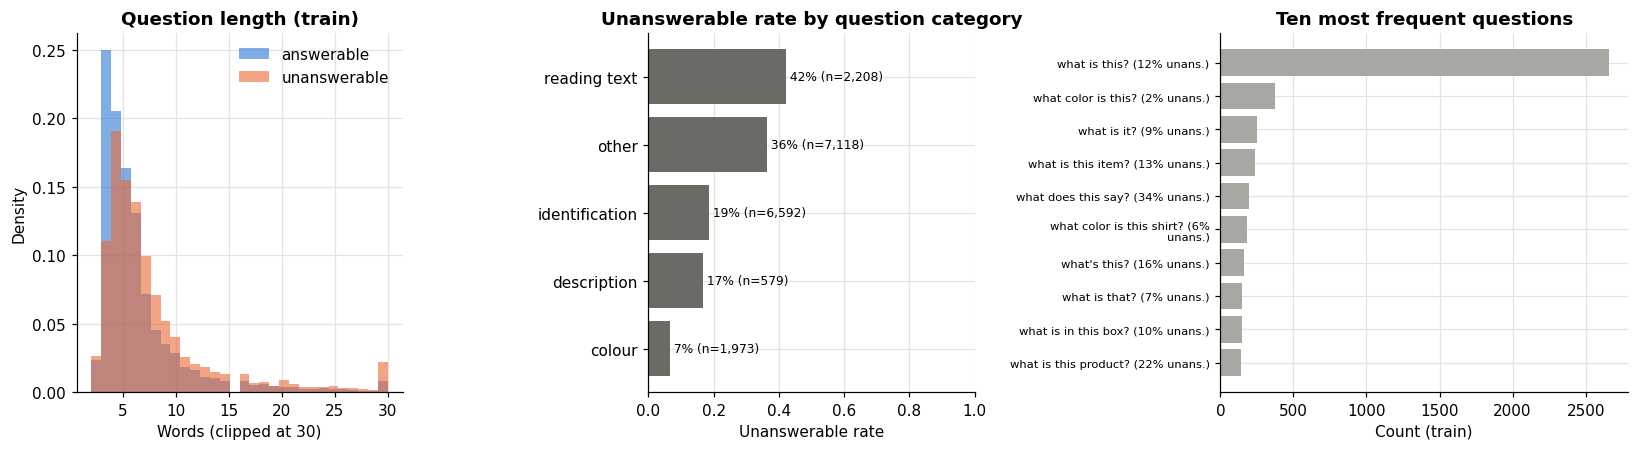

In [ ]:
def question_category(q):
    q = q.lower()
    if re.search(r"\b(say|read|written|text|label|expir|brand|name|number|title)\b", q):
        return "reading text"
    if re.search(r"\b(colou?r)\b", q):
        return "colour"
    if re.search(r"\b(what is (this|that|it)|what's (this|that)|what (kind|type))\b", q):
        return "identification"
    if re.search(r"\b(describe|look like|see)\b", q):
        return "description"
    return "other"


meta["q_words"] = meta["question"].str.split().str.len()
meta["q_category"] = meta["question"].apply(question_category)
tr = meta.iloc[IDX["train"]]
TOP_QUESTIONS = tr["question"].str.lower().value_counts().head(20)
meta["frequent_question"] = meta["question"].str.lower().isin(TOP_QUESTIONS.index).astype(int)

TEXT_STATS = {
    "question_words_median": float(tr["q_words"].median()),
    "question_words_p95": float(tr["q_words"].quantile(0.95)),
    "duplicate_question_share": round(float(tr["question"].str.lower().duplicated(keep=False).mean()), 3),
    "unans_votes_mean_unanswerable": round(float(tr.loc[tr.y == 1, "unans_votes"].mean()), 2),
    "ambiguous_share_3_to_7_votes": round(float(tr["unans_votes"].between(3, 7).mean()), 3),
}
print(json.dumps(TEXT_STATS, indent=2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for lab, name, colour in ((0, "answerable", "#2a78d6"), (1, "unanswerable", "#eb6834")):
    ax[0].hist(tr.loc[tr.y == lab, "q_words"].clip(upper=30), bins=30, alpha=0.6, density=True,
               color=colour, label=name)
ax[0].set(title="Question length (train)", xlabel="Words (clipped at 30)", ylabel="Density")
ax[0].legend()
cat = tr.groupby("q_category")["y"].agg(["mean", "size"]).sort_values("mean")
ax[1].barh(cat.index, cat["mean"], color="#6b6a65")
for i, (m, n) in enumerate(zip(cat["mean"], cat["size"])):
    ax[1].text(m, i, f" {m:.0%} (n={n:,})", va="center", fontsize=8)
ax[1].set(title="Unanswerable rate by question category", xlabel="Unanswerable rate", xlim=(0, 1))
top = TOP_QUESTIONS.head(10)
rates = [tr.loc[tr.question.str.lower() == q, "y"].mean() for q in top.index]
ax[2].barh(range(len(top))[::-1], top.values, color="#a8a7a1")
ax[2].set_yticks(range(len(top))[::-1], ["\n".join(textwrap.wrap(f"{q} ({r:.0%} unans.)", 34)) for q, r in zip(top.index, rates)], fontsize=7.5)
ax[2].set(title="Ten most frequent questions", xlabel="Count (train)")
fig.tight_layout(w_pad=1.5)
savefig(fig, "eda_text")

Image quality sample:   0%|          | 0/1500 [00:00<?, ?it/s]

,median_answerable,median_unanswerable,single_feature_auroc,separation,higher_for,mann_whitney_p
measure,,,,,,
log_sharpness,4.2378,3.5469,0.3503,0.6497,answerable,0.0000
brightness,0.4370,0.4232,0.4733,0.5267,answerable,0.0738
contrast,0.2316,0.2342,0.5095,0.5095,unanswerable,0.5222
dark_share,0.0502,0.0703,0.5244,0.5244,unanswerable,0.1011
bright_share,0.0296,0.0337,0.5211,0.5211,unanswerable,0.1573
entropy,4.3991,4.3340,0.4538,0.5462,answerable,0.0020
edge_density,0.1088,0.0759,0.3729,0.6271,answerable,0.0000
colourfulness,0.1675,0.1353,0.4175,0.5825,answerable,0.0000
log_megapixels,0.6919,0.6919,0.5099,0.5099,unanswerable,0.4828


Unreadable photos in the sample: 0


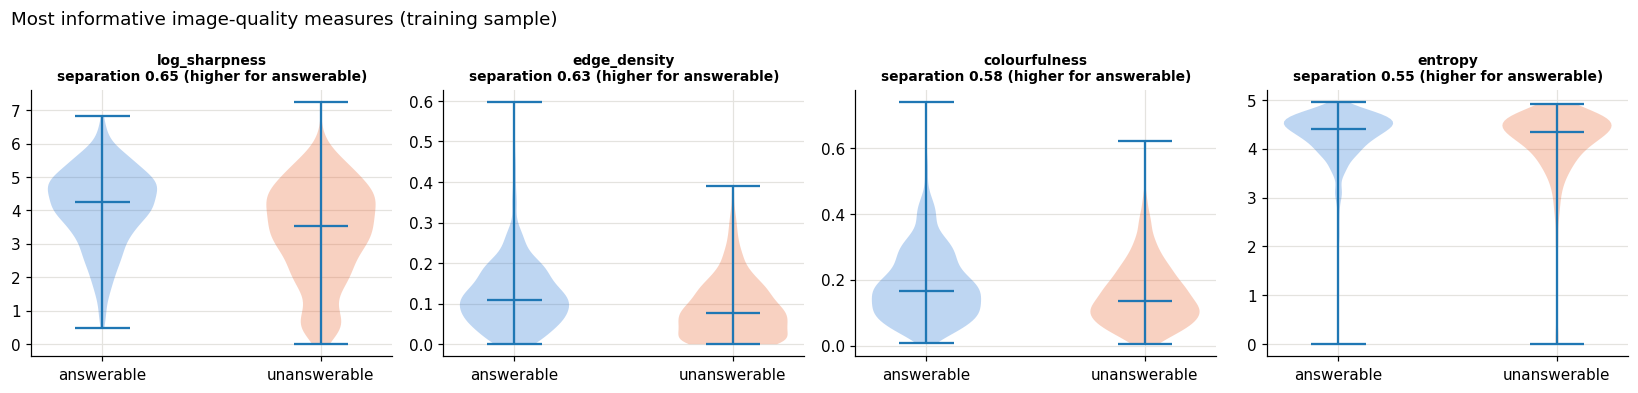

In [ ]:
from PIL import Image, ImageOps
from scipy import ndimage
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

QUALITY_NAMES = ["log_sharpness", "brightness", "contrast", "dark_share", "bright_share", "entropy",
                 "edge_density", "colourfulness", "log_megapixels", "aspect_ratio"]


def load_photo(path, draft):
    with Image.open(path) as im:
        full = im.size
        im.draft("RGB", (draft, draft))
        return ImageOps.exif_transpose(im).convert("RGB"), full


def quality_vector(im, full_size):
    small = im.copy()
    small.thumbnail((CONFIG["quality_size"], CONFIG["quality_size"]))
    rgb = np.asarray(small, np.float32) / 255.0
    g = rgb @ np.array([0.299, 0.587, 0.114], np.float32)
    sharp = np.log1p(ndimage.laplace(g).var() * 1e4)
    hist = np.histogram(g, bins=32, range=(0, 1))[0] / g.size
    entropy = float(-(hist[hist > 0] * np.log2(hist[hist > 0])).sum())
    edges = float((np.hypot(ndimage.sobel(g, 0), ndimage.sobel(g, 1)) > 0.5).mean())
    rg, yb = rgb[..., 0] - rgb[..., 1], 0.5 * (rgb[..., 0] + rgb[..., 1]) - rgb[..., 2]
    colourful = float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))
    w, h = small.size
    return np.array([sharp, g.mean(), g.std(), (g < 0.1).mean(), (g > 0.9).mean(), entropy, edges,
                     colourful, np.log(full_size[0] * full_size[1] / 1e6), w / h], np.float32)


rng = np.random.default_rng(CONFIG["seed"])
sample = pd.concat([d.sample(min(len(d), CONFIG["n_explore_images"] // 2), random_state=CONFIG["seed"])
                    for _, d in tr.groupby("y")])
q_rows, unreadable = [], 0
for p in tqdm(sample["path"], desc="Image quality sample"):
    try:
        im, full = load_photo(p, 2 * CONFIG["image_size"])
        q_rows.append(quality_vector(im, full))
    except Exception:
        q_rows.append(np.full(len(QUALITY_NAMES), np.nan, np.float32))
        unreadable += 1
QS = pd.DataFrame(q_rows, columns=QUALITY_NAMES, index=sample.index).assign(y=sample["y"].values)

rows = []
for f in QUALITY_NAMES:
    d = QS[[f, "y"]].dropna()
    a, u = d.loc[d.y == 0, f], d.loc[d.y == 1, f]
    rows.append({"measure": f, "median_answerable": a.median(), "median_unanswerable": u.median(),
                 "single_feature_auroc": roc_auc_score(d["y"], d[f]),
                 "separation": max(roc_auc_score(d["y"], d[f]), 1 - roc_auc_score(d["y"], d[f])),
                 "higher_for": "unanswerable" if roc_auc_score(d["y"], d[f]) > 0.5 else "answerable",
                 "mann_whitney_p": mannwhitneyu(a, u).pvalue})
IMAGE_STATS = pd.DataFrame(rows).set_index("measure")
display(IMAGE_STATS.round(4))
IMAGE_STATS.round(4).to_csv(TAB_DIR / "image_quality_by_label.csv")
print(f"Unreadable photos in the sample: {unreadable}")

key = IMAGE_STATS["separation"].sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, f in zip(ax, key):
    data = [QS.loc[QS.y == 0, f].dropna(), QS.loc[QS.y == 1, f].dropna()]
    parts = a.violinplot(data, showmedians=True)
    for body, colour in zip(parts["bodies"], ("#2a78d6", "#eb6834")):
        body.set_facecolor(colour)
    a.set_xticks([1, 2], ["answerable", "unanswerable"])
    a.set_title(f"{f}\nseparation {IMAGE_STATS.loc[f, 'separation']:.2f} "
                f"(higher for {IMAGE_STATS.loc[f, 'higher_for']})", fontsize=9)
fig.suptitle("Most informative image-quality measures (training sample)", x=0.01, ha="left")
fig.tight_layout()
savefig(fig, "eda_image_quality")

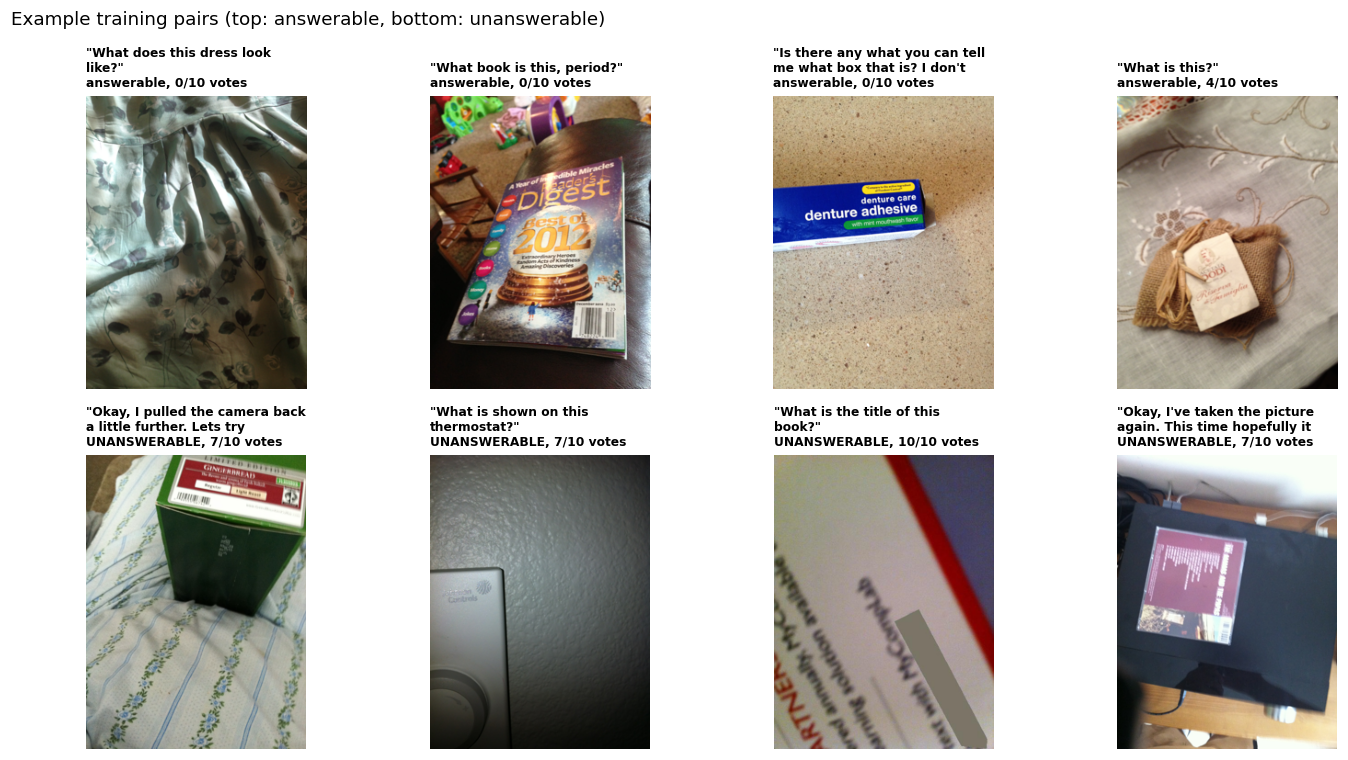

In [ ]:
import textwrap

ex = pd.concat([tr[tr.y == 0].sample(4, random_state=1), tr[tr.y == 1].sample(4, random_state=1)])
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for a, (_, r) in zip(axes.ravel(), ex.iterrows()):
    try:
        im, _ = load_photo(r["path"], 320)
        im.thumbnail((320, 320))
        a.imshow(im)
    except Exception:
        a.text(0.5, 0.5, "unreadable", ha="center")
    a.axis("off")
    label = "UNANSWERABLE" if r["y"] == 1 else "answerable"
    a.set_title("\n".join(textwrap.wrap(f'"{r["question"]}"', 32)[:2]) + f"\n{label}, "
                f"{r['unans_votes']}/10 votes", fontsize=8, loc="left")
fig.suptitle("Example training pairs (top: answerable, bottom: unanswerable)", x=0.01, ha="left")
fig.tight_layout()
savefig(fig, "eda_examples")

## 5. Preprocessing pipelines and frozen feature extraction

**Encoder choice.** CLIP ViT-B/16 (Radford et al. 2021) encodes both modalities. Because CLIP was trained to align photos with text, its photo and question embeddings live in one shared space, so their cosine similarity measures whether the question fits the photo, which is directly relevant to answerability. The encoder is frozen: only the small fusion models are trained, which keeps training to minutes on a T4 and avoids overfitting 20,000 pairs.

**Image pipeline.** Decode at reduced resolution (JPEG draft mode, for speed), apply the EXIF rotation, convert to RGB, then **letterbox**: scale the longest side to 224 pixels and pad to a square with the CLIP mean colour. Centre-cropping, CLIP's default, is avoided on purpose: in VizWiz the object is often at the edge of a badly framed photo, and cropping would remove exactly the evidence the task depends on. The ten quality measures from section 4 are computed from the same decoded photo. Outputs: a 512-d image embedding, 49 region tokens (the 14 x 14 patch grid average-pooled to 7 x 7) and the quality vector. Unreadable files are flagged and given a zero image and the training median quality.

**Text pipeline.** Whitespace normalised (section 3), CLIP's lower-casing byte-pair tokenizer, padded or truncated to 32 tokens (the share truncated is reported). Outputs: a 512-d question embedding and the 32 token states with their padding mask.

**After extraction.** Embeddings are L2-normalised; the question-photo cosine similarity is added; quality measures are imputed with the training median and standardised with training statistics only. Features are cached on Drive under a fingerprint of the image list, questions and preprocessing settings.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
PAD_COLOUR = tuple(int(round(255 * m)) for m in CLIP_MEAN)


def load_clip(name):
    from transformers import AutoTokenizer, CLIPModel
    return CLIPModel.from_pretrained(name).to(DEVICE).eval(), AutoTokenizer.from_pretrained(name)


def letterbox(im, size):
    w, h = im.size
    s = size / max(w, h)
    im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.Resampling.BICUBIC)
    canvas = Image.new("RGB", (size, size), PAD_COLOUR)
    canvas.paste(im, ((size - im.size[0]) // 2, (size - im.size[1]) // 2))
    return canvas


class PhotoSet(Dataset):
    def __init__(self, paths):
        self.paths, self.size = list(paths), CONFIG["image_size"]
        self.mean = torch.tensor(CLIP_MEAN).view(3, 1, 1)
        self.std = torch.tensor(CLIP_STD).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            im, full = load_photo(self.paths[i], 2 * self.size)
            q = quality_vector(im, full)
            x = torch.from_numpy(np.asarray(letterbox(im, self.size), np.float32) / 255.0).permute(2, 0, 1)
            return (x - self.mean) / self.std, torch.from_numpy(q), 1
        except Exception:
            return (torch.zeros(3, self.size, self.size), torch.full((len(QUALITY_NAMES),), float("nan")), 0)

In [ ]:
FINGERPRINT = hashlib.md5(("|".join(meta["image"]) + "|" + "|".join(meta["question"]) + json.dumps(
    {k: CONFIG[k] for k in ("clip_model", "image_size", "patch_grid", "max_q_tokens", "quality_size")})
    + "|prep-v1").encode()).hexdigest()[:12]
FEATURE_NAMES = ["img_emb", "img_tok", "quality", "img_ok", "txt_emb", "txt_tok", "txt_mask", "q_ntok"]
feat_file = lambda n: FEAT_DIR / f"{n}_{FINGERPRINT}.npy"
EXTRACT_LOG = FEAT_DIR / f"extraction_{FINGERPRINT}.json"


def peak_vram_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


@torch.no_grad()
def extract_images(paths, model):
    dl = DataLoader(PhotoSet(paths), batch_size=CONFIG["extract_batch_size"], num_workers=CONFIG["num_workers"],
                    pin_memory=(DEVICE == "cuda"))
    n, g = len(paths), CONFIG["patch_grid"]
    d, p = model.config.vision_config.hidden_size, model.config.projection_dim
    emb, tok = np.empty((n, p), np.float16), np.empty((n, g * g, d), np.float16)
    qual, ok = np.empty((n, len(QUALITY_NAMES)), np.float32), np.empty(n, np.uint8)
    i = 0
    for x, q, flag in tqdm(dl, desc="CLIP image features"):
        x = x.to(DEVICE, non_blocking=True)
        with autocast():
            out = model.vision_model(pixel_values=x)
            e = model.visual_projection(out.pooler_output)
        h = out.last_hidden_state[:, 1:].float()                  # patch tokens, [CLS] removed
        b, side = len(x), int(round(h.shape[1] ** 0.5))
        grid = h.reshape(b, side, side, d).permute(0, 3, 1, 2)
        regions = F.adaptive_avg_pool2d(grid, g).flatten(2).transpose(1, 2)
        emb[i:i + b], tok[i:i + b] = e.float().cpu().numpy(), regions.cpu().numpy()
        qual[i:i + b], ok[i:i + b] = q.numpy(), flag.numpy()
        i += b
    return {"img_emb": emb, "img_tok": tok, "quality": qual, "img_ok": ok}


@torch.no_grad()
def extract_text(questions, model, tokenizer, bs=512):
    n, L = len(questions), CONFIG["max_q_tokens"]
    d, p = model.config.text_config.hidden_size, model.config.projection_dim
    emb, tok, mask = np.empty((n, p), np.float16), np.empty((n, L, d), np.float16), np.empty((n, L), np.uint8)
    n_tok = np.array([len(t) for t in tokenizer(list(questions))["input_ids"]], np.int16)
    for i in tqdm(range(0, n, bs), desc="CLIP text features"):
        enc = tokenizer(list(questions[i:i + bs]), padding="max_length", truncation=True, max_length=L,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            out = model.text_model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
            e = model.text_projection(out.pooler_output)
        emb[i:i + bs] = e.float().cpu().numpy()
        tok[i:i + bs] = out.last_hidden_state.float().cpu().numpy()
        mask[i:i + bs] = enc["attention_mask"].cpu().numpy()
    return {"txt_emb": emb, "txt_tok": tok, "txt_mask": mask, "q_ntok": n_tok}


if all(feat_file(n).exists() for n in FEATURE_NAMES):
    FEATS = {n: np.load(feat_file(n), mmap_mode="r") for n in FEATURE_NAMES}
    FEAS = json.loads(EXTRACT_LOG.read_text())
    print(f"Loaded cached features {FINGERPRINT}")
else:
    clip_model, tokenizer = load_clip(CONFIG["clip_model"])
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    FEATS = extract_images(meta["path"].tolist(), clip_model)
    t1 = time.time()
    FEATS.update(extract_text(meta["question"].tolist(), clip_model, tokenizer))
    FEAS = {"pairs": len(meta), "image_minutes": round((t1 - t0) / 60, 1),
            "images_per_sec": round(len(meta) / max(t1 - t0, 1e-9), 1),
            "text_minutes": round((time.time() - t1) / 60, 1), "peak_vram_gb": peak_vram_gb(),
            "unreadable_images": int((FEATS["img_ok"] == 0).sum())}
    for n in FEATURE_NAMES:
        np.save(feat_file(n), FEATS[n])
    FEAS["features_gb"] = round(sum(feat_file(n).stat().st_size for n in FEATURE_NAMES) / 1e9, 2)
    EXTRACT_LOG.write_text(json.dumps(FEAS, indent=2))
    del clip_model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
FEAS["truncated_questions_share"] = round(float((np.asarray(FEATS["q_ntok"]) > CONFIG["max_q_tokens"]).mean()), 4)
print(json.dumps(FEAS, indent=2))

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP image features:   0%|          | 0/389 [00:00<?, ?it/s]

CLIP text features:   0%|          | 0/49 [00:00<?, ?it/s]

{
  "pairs": 24842,
  "image_minutes": 11.2,
  "images_per_sec": 36.9,
  "text_minutes": 0.4,
  "peak_vram_gb": 1.27,
  "unreadable_images": 0,
  "features_gb": 2.74,
  "truncated_questions_share": 0.0187
}


In [ ]:
def l2n(a):
    a = np.asarray(a, np.float32)
    return a / np.clip(np.linalg.norm(a, axis=1, keepdims=True), 1e-6, None)


q_emb, v_emb = l2n(FEATS["txt_emb"]), l2n(FEATS["img_emb"])
quality = np.asarray(FEATS["quality"], np.float32).copy()
tr_idx = IDX["train"]
q_median = np.nanmedian(quality[tr_idx], axis=0)
quality = np.where(np.isnan(quality), q_median, quality)
q_mu, q_sd = quality[tr_idx].mean(0), quality[tr_idx].std(0) + 1e-6       # training statistics only
quality = np.clip((quality - q_mu) / q_sd, -5, 5)
cosine = (q_emb * v_emb).sum(1, keepdims=True)

X = {"q_emb": torch.from_numpy(q_emb), "v_emb": torch.from_numpy(v_emb),
     "quality": torch.from_numpy(quality.astype(np.float32)), "cos": torch.from_numpy(cosine),
     "q_tok": torch.from_numpy(np.ascontiguousarray(FEATS["txt_tok"])),
     "q_mask": torch.from_numpy(np.ascontiguousarray(FEATS["txt_mask"])).bool(),
     "v_tok": torch.from_numpy(np.ascontiguousarray(FEATS["img_tok"]))}
meta["clip_cosine"] = cosine[:, 0]
meta["sharpness"] = np.asarray(FEATS["quality"])[:, 0]
meta["brightness"] = np.asarray(FEATS["quality"])[:, 1]
DIMS = {k: tuple(v.shape[1:]) for k, v in X.items()}
print("Model inputs:", DIMS)
print(f"In memory: {sum(v.element_size() * v.nelement() for v in X.values()) / 1e9:.2f} GB")
cos_auc = roc_auc_score(Y[tr_idx], cosine[tr_idx, 0])
print(f"Question-photo cosine similarity alone: train separation {max(cos_auc, 1 - cos_auc):.3f} "
      f"({'higher' if cos_auc > 0.5 else 'lower'} similarity = more likely unanswerable)")


def batch(idx, needs, override=None):
    idx = torch.as_tensor(np.asarray(idx))
    out = {}
    for k in needs:
        if override and k in override:
            out[k] = override[k].to(DEVICE).expand(len(idx), *X[k].shape[1:]).float()
        else:
            v = X[k][idx].to(DEVICE, non_blocking=True)
            out[k] = v if k == "q_mask" else v.float()
    return out

Model inputs: {'q_emb': (512,), 'v_emb': (512,), 'quality': (10,), 'cos': (1,), 'q_tok': (32, 512), 'q_mask': (32,), 'v_tok': (49, 768)}
In memory: 2.79 GB
Question-photo cosine similarity alone: train separation 0.534 (lower similarity = more likely unanswerable)


## 6. Models

Two single-modality baselines measure how much each modality carries alone; four fusion strategies cover the early / late / intermediate taxonomy (Baltrusaitis, Ahuja & Morency 2019). Every model maps one pair to one logit (positive = unanswerable).

| Model | Inputs | Fusion level | Idea |
|---|---|---|---|
| Question-only | question embedding | none | language prior: some questions are rarely answerable |
| Image-only | photo embedding + 10 quality measures | none | photo quality alone |
| Early fusion | q, v, q*v, abs(q-v), cosine, quality | early | one MLP over concatenated features plus explicit interaction terms from CLIP's shared space |
| Late fusion | the two baseline logits | late | logistic-regression stacker fitted on dev (3 parameters) |
| Cross-attention | 32 question tokens, 49 photo regions, quality | intermediate | 2 layers of bidirectional cross-attention (Vaswani et al. 2017; Tsai et al. 2019): question words look at photo regions and regions look at words |
| Quality-gated fusion | q, v, quality, cosine | intermediate | gated multimodal unit (Arevalo et al. 2017) whose gate also sees the quality measures, so it can lean on the question when the photo is poor; modality dropout during training |

In [ ]:
class Head(nn.Module):
    def __init__(self, d_in, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, hidden), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


class QuestionOnly(nn.Module):
    needs = ("q_emb",)

    def __init__(self, hidden, dropout):
        super().__init__()
        self.head = Head(DIMS["q_emb"][0], hidden, dropout)

    def forward(self, b):
        return self.head(b["q_emb"])


class ImageOnly(nn.Module):
    needs = ("v_emb", "quality")

    def __init__(self, hidden, dropout):
        super().__init__()
        self.head = Head(DIMS["v_emb"][0] + DIMS["quality"][0], hidden, dropout)

    def forward(self, b):
        return self.head(torch.cat([b["v_emb"], b["quality"]], -1))


class EarlyFusion(nn.Module):
    needs = ("q_emb", "v_emb", "quality", "cos")

    def __init__(self, hidden, dropout):
        super().__init__()
        d = DIMS["q_emb"][0]
        self.head = Head(4 * d + DIMS["quality"][0] + 1, hidden, dropout)

    def forward(self, b):
        q, v = b["q_emb"], b["v_emb"]
        return self.head(torch.cat([q, v, q * v, (q - v).abs(), b["cos"], b["quality"]], -1))


class CrossBlock(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.ln_q1, self.ln_v1, self.ln_q2, self.ln_v2 = (nn.LayerNorm(d) for _ in range(4))
        self.q_from_v = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.v_from_q = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ff_q = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.ff_v = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))

    def forward(self, q, mask, v):
        qn, vn = self.ln_q1(q), self.ln_v1(v)
        q = q + self.q_from_v(qn, vn, vn, need_weights=False)[0]
        v = v + self.v_from_q(vn, qn, qn, key_padding_mask=~mask, need_weights=False)[0]
        q = q + self.ff_q(self.ln_q2(q))
        v = v + self.ff_v(self.ln_v2(v))
        return q, v


class CrossAttentionFusion(nn.Module):
    needs = ("q_tok", "q_mask", "v_tok", "quality")

    def __init__(self, d_model, heads, layers, dropout, lr=None):
        super().__init__()
        (lq, dq), (lv, dv) = DIMS["q_tok"], DIMS["v_tok"]
        self.q_proj, self.v_proj = nn.Linear(dq, d_model), nn.Linear(dv, d_model)
        self.q_pos = nn.Parameter(torch.zeros(lq, d_model))
        self.v_pos = nn.Parameter(torch.zeros(lv, d_model))
        nn.init.normal_(self.q_pos, std=0.02)
        nn.init.normal_(self.v_pos, std=0.02)
        self.blocks = nn.ModuleList(CrossBlock(d_model, heads, dropout) for _ in range(layers))
        self.ln = nn.LayerNorm(d_model)
        self.head = Head(3 * d_model + DIMS["quality"][0], 256, 0.3)

    def forward(self, b):
        mask = b["q_mask"]
        q = self.q_proj(b["q_tok"]) + self.q_pos
        v = self.v_proj(b["v_tok"]) + self.v_pos
        for blk in self.blocks:
            q, v = blk(q, mask, v)
        q, v = self.ln(q), self.ln(v)
        m = mask.unsqueeze(-1).float()
        q_pool = (q * m).sum(1) / m.sum(1).clamp(min=1)
        v_pool = v.mean(1)
        return self.head(torch.cat([q_pool, v_pool, q_pool * v_pool, b["quality"]], -1))


class QualityGatedFusion(nn.Module):
    needs = ("q_emb", "v_emb", "quality", "cos")

    def __init__(self, hidden, dropout, modality_dropout):
        super().__init__()
        dq, dv, dk = DIMS["q_emb"][0], DIMS["v_emb"][0], DIMS["quality"][0]
        self.h_q, self.h_v = nn.Linear(dq, hidden), nn.Linear(dv + dk, hidden)
        self.gate = nn.Linear(dq + dv + dk + 1, hidden)
        self.head = Head(hidden + 1, hidden, dropout)
        self.p = modality_dropout
        self.last_gate = None

    def forward(self, b):
        q, v, k, c = b["q_emb"], b["v_emb"], b["quality"], b["cos"]
        if self.training and self.p > 0:
            u = torch.rand(len(q), 1, device=q.device)
            drop_q, drop_v = u < self.p / 2, (u >= self.p / 2) & (u < self.p)
            q, c = q * ~drop_q, c * ~drop_q
            v, k = v * ~drop_v, k * ~drop_v
        z = torch.sigmoid(self.gate(torch.cat([q, v, k, c], -1)))
        h = z * torch.tanh(self.h_q(q)) + (1 - z) * torch.tanh(self.h_v(torch.cat([v, k], -1)))
        self.last_gate = z.mean(-1).detach()
        return self.head(torch.cat([h, c], -1))


REGISTRY = {"question_only": QuestionOnly, "image_only": ImageOnly, "early": EarlyFusion,
            "cross_attention": CrossAttentionFusion, "gated": QualityGatedFusion}
DISPLAY = {"question_only": "Question-only", "image_only": "Image-only", "early": "Early fusion",
           "late": "Late fusion", "cross_attention": "Cross-attention", "gated": "Gated fusion"}
TRAINABLE = list(REGISTRY)


def build(name):
    hp = {k: v for k, v in CONFIG["models"][name].items() if k != "lr"}
    return REGISTRY[name](**hp)


n_params = {DISPLAY[n]: sum(p.numel() for p in build(n).parameters()) for n in TRAINABLE}
print({k: f"{v:,}" for k, v in n_params.items()})

{'Question-only': '132,609', 'Image-only': '135,189', 'Early fusion': '1,059,351', 'Cross-attention': '2,659,093', 'Gated fusion': '597,251'}


## 7. Training

**Protocol (identical for every model).** Binary cross-entropy with the positive class weighted by the train ratio of answerable to unanswerable pairs (class imbalance); AdamW (Loshchilov & Hutter 2019) with weight decay 0.01, one warm-up epoch then cosine decay, gradient clipping at 1.0, batch 256. Each epoch the model is scored on dev; the epoch with the best dev AUPRC is kept and training stops after 4 epochs without improvement. Train loss is measured in evaluation mode on a fixed 4,000-pair training subset so it is comparable with the dev loss (learning curves). Every trainable model is trained with three seeds.

**Late fusion** is fitted after the baselines: a logistic regression on the two baseline logits, fitted on dev predictions (3 parameters, so little room to overfit), then scored on test.

Each run is saved to `runs/<model>/seed<k>/` (weights, history, predictions, summary). A later session reuses a run when its configuration hash and feature fingerprint match, so results are reproducible and the notebook re-runs quickly.

In [ ]:
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression


def bce(p, y, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())


@torch.no_grad()
def predict(model, idx, override=None, bs=1024):
    model.eval()
    probs, gates = [], []
    for i in range(0, len(idx), bs):
        logits = model(batch(idx[i:i + bs], model.needs, override))
        probs.append(torch.sigmoid(logits).float().cpu())
        if getattr(model, "last_gate", None) is not None:
            gates.append(model.last_gate.float().cpu())
    return torch.cat(probs).numpy(), (torch.cat(gates).numpy() if gates else None)


def train_model(name, seed):
    set_seed(seed)
    t = {**CONFIG["train"], **({"lr": CONFIG["models"][name]["lr"]} if "lr" in CONFIG["models"][name] else {})}
    model = build(name).to(DEVICE)
    tr, dev = IDX["train"], IDX["dev"]
    y = torch.from_numpy(Y)
    pos = float(Y[tr].mean())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - pos) / pos, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=t["lr"], weight_decay=t["weight_decay"])
    spe = math.ceil(len(tr) / t["batch_size"])
    total, warm = t["epochs"] * spe, max(1, t["warmup_epochs"] * spe)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    rng = np.random.default_rng(seed)
    probe = rng.choice(tr, size=min(len(tr), t["train_probe"]), replace=False)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    hist, best, best_state, bad = [], -1.0, None, 0
    for epoch in range(1, t["epochs"] + 1):
        model.train()
        t0 = time.time()
        order = rng.permutation(tr)
        for i in range(0, len(order), t["batch_size"]):
            b = order[i:i + t["batch_size"]]
            loss = loss_fn(model(batch(b, model.needs)), y[b].to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), t["grad_clip"])
            opt.step()
            sched.step()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        secs = time.time() - t0
        p_probe, _ = predict(model, probe)
        p_dev, _ = predict(model, dev)
        ap = float(average_precision_score(Y[dev], p_dev))
        hist.append({"epoch": epoch, "train_loss": bce(p_probe, Y[probe]), "dev_loss": bce(p_dev, Y[dev]),
                     "dev_auprc": ap, "seconds": round(secs, 2)})
        if ap > best:
            best, best_state, bad = ap, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= t["patience"]:
                break
    model.load_state_dict(best_state)
    info = {"params": int(sum(p.numel() for p in model.parameters())), "epochs_run": len(hist),
            "best_epoch": int(pd.DataFrame(hist)["dev_auprc"].idxmax()) + 1, "best_dev_auprc": round(best, 4),
            "sec_per_epoch": round(float(np.mean([h["seconds"] for h in hist])), 2), "peak_vram_gb": peak_vram_gb()}
    return model, pd.DataFrame(hist), info


def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def save_run(name, seed, preds, hist=None, info=None, model=None):
    d = RUN_DIR / name / f"seed{seed}"
    d.mkdir(parents=True, exist_ok=True)
    rows = []
    for sp in ("dev", "test"):
        f = pd.DataFrame({"image": meta["image"].values[IDX[sp]], "split": sp, "y": Y[IDX[sp]].astype(int),
                          "p_unanswerable": preds[sp]})
        if preds.get(f"gate_{sp}") is not None:
            f["gate_q"] = preds[f"gate_{sp}"]
        rows.append(f)
    pd.concat(rows).to_csv(d / "predictions.csv", index=False)
    if hist is not None:
        hist.to_csv(d / "history.csv", index=False)
    if model is not None:
        torch.save(model.state_dict(), d / "model.pt")
    (d / "summary.json").write_text(json.dumps({**(info or {}), "model": name, "seed": seed,
                                                "config_hash": CONFIG_HASH, "features": FINGERPRINT}, indent=2))


def load_run(name, seed, need_model):
    d = RUN_DIR / name / f"seed{seed}"
    if not (d / "summary.json").exists():
        return None
    info = json.loads((d / "summary.json").read_text())
    if info.get("config_hash") != CONFIG_HASH or info.get("features") != FINGERPRINT:
        return None
    p = pd.read_csv(d / "predictions.csv")
    preds = {sp: p.loc[p.split == sp, "p_unanswerable"].values for sp in ("dev", "test")}
    if "gate_q" in p:
        preds.update({f"gate_{sp}": p.loc[p.split == sp, "gate_q"].values for sp in ("dev", "test")})
    model = None
    if need_model and (d / "model.pt").exists():
        model = build(name).to(DEVICE)
        model.load_state_dict(torch.load(d / "model.pt", map_location=DEVICE))
        model.eval()
    hist = pd.read_csv(d / "history.csv") if (d / "history.csv").exists() else None
    return preds, hist, info, model

In [ ]:
RESULTS, HISTORY, COSTS, MODELS, LATE_WEIGHTS = {}, {}, {}, {}, {}
t_start = time.time()
for seed in CONFIG["seeds"]:
    RESULTS[seed], HISTORY[seed], COSTS[seed] = {}, {}, {}
    for name in TRAINABLE:
        cached = load_run(name, seed, need_model=(seed == CONFIG["seed"]))
        if cached is not None and (seed != CONFIG["seed"] or cached[3] is not None):
            preds, hist, info, model = cached
            status = "cached"
        else:
            model, hist, info = train_model(name, seed)
            preds = {}
            for sp in ("dev", "test"):
                preds[sp], preds[f"gate_{sp}"] = predict(model, IDX[sp])
            save_run(name, seed, preds, hist, info, model)
            status = f"trained ({info['epochs_run']} epochs)"
        RESULTS[seed][name], HISTORY[seed][name], COSTS[seed][name] = preds, hist, info
        if seed == CONFIG["seed"]:
            MODELS[name] = model
        print(f"seed {seed} | {DISPLAY[name]:16s} | dev AUPRC {info['best_dev_auprc']:.4f} | {status}")
    # late fusion: logistic stacker on the two baseline logits, fitted on dev only
    q, v = RESULTS[seed]["question_only"], RESULTS[seed]["image_only"]
    Z = {sp: np.c_[logit(q[sp]), logit(v[sp])] for sp in ("dev", "test")}
    stack = LogisticRegression(C=1.0, max_iter=1000).fit(Z["dev"], Y[IDX["dev"]])
    late = {sp: stack.predict_proba(Z[sp])[:, 1] for sp in ("dev", "test")}
    LATE_WEIGHTS[seed] = {"question": round(float(stack.coef_[0, 0]), 3), "image": round(float(stack.coef_[0, 1]), 3),
                          "bias": round(float(stack.intercept_[0]), 3)}
    info = {"params": 3, "epochs_run": 0, "best_dev_auprc": round(float(average_precision_score(
        Y[IDX["dev"]], late["dev"])), 4), **{f"weight_{k}": round(w, 3) for k, w in LATE_WEIGHTS[seed].items()}}
    save_run("late", seed, late, info=info)
    RESULTS[seed]["late"], COSTS[seed]["late"] = late, info
    print(f"seed {seed} | {'Late fusion':16s} | dev AUPRC {info['best_dev_auprc']:.4f} | weights {LATE_WEIGHTS[seed]}")
TRAIN_MINUTES = round((time.time() - t_start) / 60, 1)
print(f"Training stage: {TRAIN_MINUTES} min")

seed 0 | Question-only    | dev AUPRC 0.5191 | trained (10 epochs)
seed 0 | Image-only       | dev AUPRC 0.6324 | trained (12 epochs)
seed 0 | Early fusion     | dev AUPRC 0.7572 | trained (7 epochs)
seed 0 | Cross-attention  | dev AUPRC 0.7737 | trained (6 epochs)
seed 0 | Gated fusion     | dev AUPRC 0.7572 | trained (8 epochs)
seed 0 | Late fusion      | dev AUPRC 0.6971 | weights {'question': 0.885, 'image': 0.819, 'bias': -0.91}
seed 1 | Question-only    | dev AUPRC 0.5190 | trained (9 epochs)
seed 1 | Image-only       | dev AUPRC 0.6338 | trained (10 epochs)
seed 1 | Early fusion     | dev AUPRC 0.7602 | trained (11 epochs)
seed 1 | Cross-attention  | dev AUPRC 0.7834 | trained (7 epochs)
seed 1 | Gated fusion     | dev AUPRC 0.7575 | trained (10 epochs)
seed 1 | Late fusion      | dev AUPRC 0.6934 | weights {'question': 0.893, 'image': 0.873, 'bias': -0.796}
seed 2 | Question-only    | dev AUPRC 0.5150 | trained (11 epochs)
seed 2 | Image-only       | dev AUPRC 0.6300 | trained 

In [ ]:
config_rows = []
for name in TRAINABLE + ["late"]:
    info = COSTS[CONFIG["seed"]][name]
    hp = CONFIG["models"].get(name, {"stacker": "logistic regression on 2 logits, C=1.0"})
    config_rows.append({"model": DISPLAY[name],
                        "inputs": ", ".join(REGISTRY[name].needs) if name in REGISTRY else "baseline logits",
                        "hyperparameters": json.dumps(hp), "trainable_params": info["params"],
                        "epochs_run": info["epochs_run"], "best_epoch": info.get("best_epoch"),
                        "sec_per_epoch": info.get("sec_per_epoch"), "dev_AUPRC": info["best_dev_auprc"]})
CONFIG_TABLE = pd.DataFrame(config_rows).set_index("model")
display(CONFIG_TABLE)
CONFIG_TABLE.to_csv(TAB_DIR / "model_configurations.csv")
print("Shared training settings:", json.dumps(CONFIG["train"]))

,inputs,hyperparameters,trainable_params,epochs_run,best_epoch,sec_per_epoch,dev_AUPRC
model,,,,,,,
Question-only,q_emb,"{""hidden"": 256, ""dropout"": 0.3}",132609,10,6.0,0.34,0.5191
Image-only,"v_emb, quality","{""hidden"": 256, ""dropout"": 0.3}",135189,12,8.0,0.31,0.6324
Early fusion,"q_emb, v_emb, quality, cos","{""hidden"": 512, ""dropout"": 0.3}",1059351,7,3.0,0.40,0.7572
Cross-attention,"q_tok, q_mask, v_tok, quality","{""d_model"": 256, ""heads"": 4, ""layers"": 2, ""dro...",2659093,6,2.0,6.68,0.7737
Gated fusion,"q_emb, v_emb, quality, cos","{""hidden"": 256, ""dropout"": 0.3, ""modality_drop...",597251,8,4.0,0.34,0.7572
Late fusion,baseline logits,"{""stacker"": ""logistic regression on 2 logits, ...",3,0,NaN,NaN,0.6971


Shared training settings: {"epochs": 25, "batch_size": 256, "lr": 0.001, "weight_decay": 0.01, "patience": 4, "warmup_epochs": 1, "grad_clip": 1.0, "train_probe": 4000}


## 8. Evaluation

The next cell writes the evaluation toolkit (my module from the group phase, `evaluation.py`) to the Colab disk and imports it. It contains the metrics, the paired bootstrap, the significance tests and the figure functions; the cells after it apply them to the models above.

Methods: percentile bootstrap 95% CIs (Efron & Tibshirani 1993) on shared resamples so model differences are paired; exact McNemar test (McNemar 1947; Dietterich 1998) with Holm (1979) correction; expected calibration error (Guo et al. 2017) and Brier score (Brier 1950); AUPRC alongside AUROC because unanswerable pairs are the minority (Saito & Rehmsmeier 2015).

In [ ]:
%%writefile /content/evaluation.py

from __future__ import annotations

import json
import time
from pathlib import Path
from typing import Callable, Dict, Iterable, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, rankdata
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

LABELS = ("Answerable", "Unanswerable")
UNIMODAL = ("Question-only", "Image-only")

# Colour follows the model, never its rank. Single-modality baselines are neutral
# greys; fusion models take the reference categorical slots in fixed order.
INK, INK_2, INK_3, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
COLOURS = {
    "Question-only": "#a8a7a1",
    "Image-only": "#6b6a65",
    "Early fusion": "#2a78d6",
    "Late fusion": "#eb6834",
    "Cross-attention": "#1baf7a",
    "Gated fusion": "#6250d6",
    "CLIP reference": "#e87ba4",
}
_SPARE = ["#008300", "#e34948", "#eda100"]

METRIC_NAMES = {
    "macro_f1": "Macro-F1",
    "f1_unans": "F1 (unanswerable)",
    "f1_ans": "F1 (answerable)",
    "precision_unans": "Precision (unans.)",
    "recall_unans": "Recall (unans.)",
    "specificity": "Specificity",
    "balanced_acc": "Balanced accuracy",
    "accuracy": "Accuracy",
    "mcc": "MCC",
    "auroc": "AUROC",
    "auprc": "AUPRC",
    "brier": "Brier score",
    "log_loss": "Log loss",
    "ece": "ECE",
}
LOWER_IS_BETTER = {"brier", "log_loss", "ece"}

# Plot style
def set_style() -> None:
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9.5,
        "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.labelsize": 9.5,
        "axes.edgecolor": INK_3, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
        "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
    })


def colour(name: str, order: Sequence[str] = ()) -> str:
    if name in COLOURS:
        return COLOURS[name]
    extra = [n for n in order if n not in COLOURS]
    return _SPARE[extra.index(name) % len(_SPARE)] if name in extra else _SPARE[0]


def savefig(fig, path: Optional[Path]) -> None:
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")



# Point metrics
def _confusion(y: np.ndarray, yhat: np.ndarray, axis=None):
    y, yhat = y.astype(bool), yhat.astype(bool)
    tp = (y & yhat).sum(axis=axis)
    fp = (~y & yhat).sum(axis=axis)
    fn = (y & ~yhat).sum(axis=axis)
    tn = (~y & ~yhat).sum(axis=axis)
    return tp, fp, fn, tn


def _safe_div(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.divide(a, b, out=np.zeros_like(a), where=b > 0)


def _threshold_metrics_from_counts(tp, fp, fn, tn) -> Dict[str, np.ndarray]:
    f1_pos = _safe_div(2 * tp, 2 * tp + fp + fn)
    f1_neg = _safe_div(2 * tn, 2 * tn + fn + fp)
    recall = _safe_div(tp, tp + fn)
    spec = _safe_div(tn, tn + fp)
    mcc_den = np.sqrt(np.asarray((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), float))
    return {
        "macro_f1": (f1_pos + f1_neg) / 2,
        "f1_unans": f1_pos,
        "f1_ans": f1_neg,
        "precision_unans": _safe_div(tp, tp + fp),
        "recall_unans": recall,
        "specificity": spec,
        "balanced_acc": (recall + spec) / 2,
        "accuracy": _safe_div(tp + tn, tp + fp + fn + tn),
        "mcc": _safe_div(tp * tn - fp * fn, mcc_den),
    }


def expected_calibration_error(p: np.ndarray, y: np.ndarray, n_bins: int = 15) -> float:
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def _auroc(p: np.ndarray, y: np.ndarray, axis: int = -1) -> np.ndarray:
    r = rankdata(p, axis=axis)
    n1 = y.sum(axis=axis)
    n0 = y.shape[axis] - n1
    return _safe_div((r * y).sum(axis=axis) - n1 * (n1 + 1) / 2, n1 * n0)


def tune_threshold(p: np.ndarray, y: np.ndarray) -> float:
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    grid = np.linspace(0.05, 0.95, 91)
    scores = _threshold_metrics_from_counts(*_confusion(y[None, :], p[None, :] >= grid[:, None], axis=1))["macro_f1"]
    return float(grid[int(np.argmax(scores))])


def all_metrics(p: np.ndarray, y: np.ndarray, t: float) -> Dict[str, float]:
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    out = {k: float(v) for k, v in _threshold_metrics_from_counts(*_confusion(y, p >= t)).items()}
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    out.update({
        "auroc": float(_auroc(p, y)),
        "auprc": float(average_precision_score(y, p)),
        "brier": float(np.mean((p - y) ** 2)),
        "log_loss": float(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))),
        "ece": expected_calibration_error(p, y),
    })
    return out


# Bootstrap and comparison tables
def make_boot_idx(n: int, n_boot: int = 1000, seed: int = 42) -> np.ndarray:
    return np.random.default_rng(seed).integers(0, n, size=(n_boot, n))


def bootstrap_distribution(p, y, t, boot_idx, metrics=("macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc")):
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    yb, pb = y[boot_idx], p[boot_idx]
    out = {}
    thr = _threshold_metrics_from_counts(*_confusion(yb, pb >= t, axis=1))
    for m in metrics:
        if m in thr:
            out[m] = thr[m]
        elif m == "auroc":
            out[m] = _auroc(pb, yb, axis=1)
        elif m == "auprc":
            out[m] = np.array([average_precision_score(yb[i], pb[i]) for i in range(len(boot_idx))])
        elif m == "brier":
            out[m] = ((pb - yb) ** 2).mean(1)
        else:
            raise ValueError(f"bootstrap not implemented for {m}")
    return out


def comparison_table(PRED, THR, y, order, split="test", boot_idx=None,
                     ci_metrics=("macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc")):

    rows, boots = [], {}
    for name in order:
        p = PRED[name][split]
        row = {"model": name, "threshold": THR[name], **all_metrics(p, y, THR[name])}
        if boot_idx is not None:
            boots[name] = bootstrap_distribution(p, y, THR[name], boot_idx, ci_metrics)
            for m, arr in boots[name].items():
                row[f"{m}_lo"], row[f"{m}_hi"] = np.percentile(arr, [2.5, 97.5])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boots


def format_table(table: pd.DataFrame, metrics: Sequence[str], digits: int = 3) -> pd.DataFrame:
    out = pd.DataFrame(index=table.index)
    for m in metrics:
        vals = table[m]
        best = vals.idxmin() if m in LOWER_IS_BETTER else vals.idxmax()
        cells = []
        for name, v in vals.items():
            s = f"{v:.{digits}f}"
            if f"{m}_lo" in table:
                s += f" [{table.loc[name, f'{m}_lo']:.{digits}f}, {table.loc[name, f'{m}_hi']:.{digits}f}]"
            cells.append(s + (" *" if name == best else ""))
        out[METRIC_NAMES.get(m, m)] = cells
    return out


def _holm(pvals: np.ndarray) -> np.ndarray:
    order = np.argsort(pvals)
    adj = np.empty_like(pvals)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(pvals) - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj


def mcnemar_exact(correct_a: np.ndarray, correct_b: np.ndarray) -> float:
    b = int((correct_a & ~correct_b).sum())
    c = int((~correct_a & correct_b).sum())
    return 1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue)


def pairwise_significance(PRED, THR, y, boots, order, split="test", metric="macro_f1", alpha=0.05):
    y = np.asarray(y).astype(int)
    correct = {n: (PRED[n][split] >= THR[n]).astype(int) == y for n in order}
    point = {n: all_metrics(PRED[n][split], y, THR[n])[metric] for n in order}
    rows = []
    for i, a in enumerate(order):
        for b in order[i + 1:]:
            d = boots[a][metric] - boots[b][metric]
            p_boot = min(1.0, max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / len(d)))
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"model_a": a, "model_b": b, "diff": point[a] - point[b], "ci_lo": lo, "ci_hi": hi,
                         "p_bootstrap": p_boot, "p_mcnemar": mcnemar_exact(correct[a], correct[b])})
    df = pd.DataFrame(rows)
    df["p_bootstrap_holm"] = _holm(df["p_bootstrap"].values)
    df["p_mcnemar_holm"] = _holm(df["p_mcnemar"].values)
    df["significant"] = (df["p_bootstrap_holm"] < alpha) & ((df["ci_lo"] > 0) | (df["ci_hi"] < 0))
    return df


def fusion_gain(table, boots, unimodal=UNIMODAL, fusions=None, metric="macro_f1"):
    """Gain of each fusion model over the best single-modality model, with paired 95% CI.
    Team goal 2: the CI must exclude zero."""
    fusions = fusions or [n for n in table.index if n not in unimodal]
    best_uni = max(unimodal, key=lambda n: table.loc[n, metric])
    rows = []
    for f in fusions:
        d = boots[f][metric] - boots[best_uni][metric]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"fusion": f, "vs": best_uni, "gain": table.loc[f, metric] - table.loc[best_uni, metric],
                     "ci_lo": lo, "ci_hi": hi, "ci_excludes_zero": bool(lo > 0 or hi < 0)})
    return pd.DataFrame(rows).set_index("fusion")


def seed_summary(tables: List[pd.DataFrame], metrics=("macro_f1", "auprc", "auroc", "f1_unans", "ece")):
    """Mean and standard deviation across seeds (one table per seed, indexed by model)."""
    allr = pd.concat(tables, keys=range(len(tables)), names=["run", "model"])
    g = allr.groupby(level="model")[list(metrics)]
    mean, std = g.mean(), g.std(ddof=1)
    out = mean.copy()
    for m in metrics:
        out[f"{m}_std"] = std[m]
    out["n_seeds"] = len(tables)
    return out.reindex([n for n in tables[0].index if n in out.index])


def format_seed_summary(summary, metrics=("macro_f1", "auprc", "auroc"), digits=3):
    out = pd.DataFrame(index=summary.index)
    for m in metrics:
        out[METRIC_NAMES.get(m, m)] = [f"{a:.{digits}f} +/- {s:.{digits}f}"
                                       for a, s in zip(summary[m], summary[f"{m}_std"])]
    return out


# Speed and size
def benchmark(fn: Callable[[], object], repeats: int = 30, warmup: int = 5,
              sync: Optional[Callable[[], None]] = None) -> Dict[str, float]:
    for _ in range(warmup):
        fn()
    if sync:
        sync()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        if sync:
            sync()
        times.append((time.perf_counter() - t0) * 1000)
    return {"median_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95))}


def efficiency_table(table, COST, latency=None, composite=None, metric="macro_f1"):

    composite = composite or {}
    rows = []
    for name in table.index:
        parts = composite.get(name, [name])
        cs = [COST[p] for p in parts if p in COST]
        vram = [c.get("peak_vram_gb") for c in cs if c.get("peak_vram_gb") is not None]
        row = {
            "model": name, metric: table.loc[name, metric], "auprc": table.loc[name, "auprc"],
            "params": int(sum(c.get("params", 0) for c in cs)),
            "train_sec": float(sum(c.get("sec_per_epoch", 0) * c.get("epochs_run", 0) for c in cs)),
            "epochs": "+".join(str(c.get("epochs_run", "")) for c in cs),
            "peak_vram_gb": max(vram) if vram else np.nan,
        }
        if latency and name in latency:
            row.update(latency[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def learning_curve_summary(HIST) -> pd.DataFrame:
    """Best epoch, losses at the best epoch and the train/dev gap (overfitting indicator)."""
    rows = []
    for name, h in HIST.items():
        b = h.loc[h["dev_auprc"].idxmax()]
        rows.append({"model": name, "epochs_run": int(h["epoch"].max()), "best_epoch": int(b["epoch"]),
                     "train_loss_best": b["train_loss"], "dev_loss_best": b["dev_loss"],
                     "gap_best": b["dev_loss"] - b["train_loss"],
                     "gap_last": h["dev_loss"].iloc[-1] - h["train_loss"].iloc[-1],
                     "dev_auprc_best": b["dev_auprc"]})
    return pd.DataFrame(rows).set_index("model")


# Failure analysis
def per_pair_predictions(meta_split: pd.DataFrame, PRED, THR, y, order, split="test") -> pd.DataFrame:
    df = meta_split.reset_index(drop=True).copy()
    df["y"] = np.asarray(y).astype(int)
    for n in order:
        p = PRED[n][split]
        df[f"p::{n}"] = p
        df[f"pred::{n}"] = (p >= THR[n]).astype(int)
        df[f"ok::{n}"] = df[f"pred::{n}"] == df["y"]
    df["n_models_wrong"] = (~df[[f"ok::{n}" for n in order]]).sum(1)
    return df


def outcome(df: pd.DataFrame, model: str) -> pd.Series:
    """TP/TN/FP/FN for one model (positive = unanswerable)."""
    y, yhat = df["y"], df[f"pred::{model}"]
    return pd.Series(np.select([(y == 1) & (yhat == 1), (y == 0) & (yhat == 0), (y == 0) & (yhat == 1)],
                               ["TP", "TN", "FP"], "FN"), index=df.index)


def complementarity(df: pd.DataFrame, fusions: Sequence[str], q="Question-only", i="Image-only") -> pd.DataFrame:
    qo, io = df[f"ok::{q}"], df[f"ok::{i}"]
    groups = {"Both right": qo & io, "Only question right": qo & ~io,
              "Only image right": ~qo & io, "Both wrong": ~qo & ~io}
    rows = []
    for g, m in groups.items():
        r = {"group": g, "share": m.mean(), "n": int(m.sum())}
        for f in fusions:
            r[f] = df.loc[m, f"ok::{f}"].mean() if m.any() else np.nan
        rows.append(r)
    out = pd.DataFrame(rows).set_index("group")
    out.attrs["oracle_accuracy"] = float((qo | io).mean())
    return out


def describe_outcomes(df: pd.DataFrame, model: str, columns: Sequence[str]) -> pd.DataFrame:
    o = outcome(df, model)
    out = df.assign(outcome=o).groupby("outcome")[list(columns)].mean()
    out.insert(0, "n", o.value_counts())
    return out.reindex(["TP", "FN", "TN", "FP"])


def top_errors(df: pd.DataFrame, model: str, kind: str = "FN", k: int = 8) -> pd.DataFrame:
    """Most confident mistakes: FN = unanswerable pairs the model was surest were answerable."""
    o = outcome(df, model)
    sub = df[o == kind]
    p = sub[f"p::{model}"]
    return sub.loc[(p if kind == "FN" else -p).sort_values().index].head(k)


def ablation_table(scores: Dict[str, Dict[str, np.ndarray]], y, THR) -> pd.DataFrame:
    rows = []
    for model, conds in scores.items():
        full = all_metrics(conds["full"], y, THR[model])
        for cond, p in conds.items():
            m = all_metrics(p, y, THR[model])
            rows.append({"model": model, "condition": cond, "auprc": m["auprc"], "macro_f1": m["macro_f1"],
                         "auprc_drop": full["auprc"] - m["auprc"], "macro_f1_drop": full["macro_f1"] - m["macro_f1"]})
    return pd.DataFrame(rows).set_index(["model", "condition"])


# Figures
def plot_metric_intervals(table, order, metrics=("macro_f1", "auprc", "auroc", "f1_unans"), path=None):
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.3 * len(metrics), 0.42 * len(order) + 1.2), sharey=True)
    ypos = np.arange(len(order))[::-1]
    for ax, m in zip(np.atleast_1d(axes), metrics):
        v = table.loc[order, m].values
        for yp, n, val in zip(ypos, order, v):
            c = colour(n, order)
            if f"{m}_lo" in table:
                ax.plot([table.loc[n, f"{m}_lo"], table.loc[n, f"{m}_hi"]], [yp, yp], color=c, lw=2,
                        solid_capstyle="round")
            ax.plot(val, yp, "o", ms=8, color=c, mec="white", mew=2)
            ax.annotate(f"{val:.3f}", (val, yp), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8, color=INK_2)
        ax.set_title(METRIC_NAMES.get(m, m))
        ax.grid(axis="y", visible=False)
        ax.margins(x=0.15)
        ax.set_ylim(-0.6, len(order) - 0.15)   # headroom so value labels clear the title
    np.atleast_1d(axes)[0].set_yticks(ypos, order)
    fig.suptitle("Test performance with 95% bootstrap confidence intervals", x=0.01, ha="left", y=1.02)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_roc_pr(PRED, y, order, split="test", path=None):
    """ROC and precision-recall curves; the PR chance line is the test prevalence."""
    y = np.asarray(y).astype(int)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
    for n in order:
        p = PRED[n][split]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        c = colour(n, order)
        a1.plot(fpr, tpr, color=c, label=f"{n} ({_auroc(p, y):.3f})")
        a2.plot(rec, prec, color=c, label=f"{n} ({average_precision_score(y, p):.3f})")
    a1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK_3)
    a2.axhline(y.mean(), ls="--", lw=1, color=INK_3)
    a2.annotate(f"chance = prevalence {y.mean():.2f}", (0.02, y.mean()), xytext=(0, 4),
                textcoords="offset points", fontsize=8, color=INK_2)
    a1.set(title="(a) ROC curve (AUROC)", xlabel="False positive rate", ylabel="True positive rate")
    a2.set(title="(b) Precision-recall curve (AUPRC)", xlabel="Recall (unanswerable)",
           ylabel="Precision (unanswerable)", ylim=(0, 1.02))
    a1.legend(loc="lower right", fontsize=8)
    a2.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_confusion_grid(PRED, THR, y, order, split="test", path=None):
    """Row-normalised confusion matrices with raw counts, one per model."""
    y = np.asarray(y).astype(int)
    fig, axes = plt.subplots(1, len(order), figsize=(2.6 * len(order), 2.9))
    for ax, n in zip(np.atleast_1d(axes), order):
        tp, fp, fn, tn = _confusion(y, PRED[n][split] >= THR[n])
        cm = np.array([[tn, fp], [fn, tp]])
        rates = cm / cm.sum(1, keepdims=True)
        ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, f"{rates[r, c]:.0%}\n({v:,})", ha="center", va="center", fontsize=8.5,
                    color="white" if rates[r, c] > 0.55 else INK)
        ax.set_xticks([0, 1], ["Ans.", "Unans."])
        ax.set_yticks([0, 1], ["Ans.", "Unans."])
        ax.set_title(n, fontsize=9.5)
        ax.set_xlabel("Predicted")
        ax.grid(False)
    np.atleast_1d(axes)[0].set_ylabel("True")
    fig.suptitle("Confusion matrices at the validation-tuned threshold (row-normalised)", x=0.01, ha="left", y=1.03)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_reliability(PRED, y, order, split="test", n_bins=10, path=None):
    """Reliability diagram plus a histogram of predicted probabilities."""
    y = np.asarray(y).astype(int)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(5.6, 6), gridspec_kw={"height_ratios": [3, 1.2]}, sharex=True)
    edges = np.linspace(0, 1, n_bins + 1)
    for n in order:
        p = PRED[n][split]
        b = np.clip(np.digitize(p, edges) - 1, 0, n_bins - 1)
        xs = [p[b == k].mean() for k in range(n_bins) if (b == k).sum() >= 20]
        ys = [y[b == k].mean() for k in range(n_bins) if (b == k).sum() >= 20]
        c = colour(n, order)
        a1.plot(xs, ys, marker="o", ms=5, color=c, label=f"{n} (ECE {expected_calibration_error(p, y):.3f})")
        a2.hist(p, bins=edges, histtype="step", color=c, lw=1.5)
    a1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK_3)
    a1.annotate("perfect calibration", (0.62, 0.66), rotation=38, fontsize=8, color=INK_2)
    a1.set(title="Calibration on test (bins with >= 20 pairs)", ylabel="Observed unanswerable rate",
           xlim=(0, 1), ylim=(0, 1))
    a1.legend(fontsize=8, loc="upper left")
    a2.set(xlabel="Predicted P(unanswerable)", ylabel="Pairs")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_significance_matrix(pairs: pd.DataFrame, order, metric_label="macro-F1", path=None):
    k = len(order)
    M = np.full((k, k), np.nan)
    sig = np.zeros((k, k), bool)
    for _, r in pairs.iterrows():
        i, j = order.index(r.model_a), order.index(r.model_b)
        M[i, j], M[j, i] = r["diff"], -r["diff"]
        sig[i, j] = sig[j, i] = r["significant"]
    lim = np.nanmax(np.abs(M)) or 1
    fig, ax = plt.subplots(figsize=(1.15 * k + 2.2, 1.0 * k + 1))
    im = ax.imshow(M, cmap="RdBu", vmin=-lim, vmax=lim)
    for i in range(k):
        for j in range(k):
            if i != j:
                ax.text(j, i, f"{M[i, j]:+.3f}" + ("\n*" if sig[i, j] else "\nn.s."), ha="center", va="center",
                        fontsize=8, color="white" if abs(M[i, j]) > 0.6 * lim else INK)
    ax.set_xticks(range(k), order, rotation=30, ha="right")
    ax.set_yticks(range(k), order)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label=f"{metric_label} difference (row - column)")
    ax.set_title(f"Pairwise {metric_label} differences\n* = 95% CI excludes 0 and Holm-corrected p < 0.05",
                 fontsize=9.5)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_learning_curves(HIST, order, path=None):
    names = [n for n in order if n in HIST]
    fig, axes = plt.subplots(2, len(names), figsize=(3.3 * len(names), 5.2), sharex="col", sharey="row")
    axes = np.array(axes).reshape(2, -1)
    for j, n in enumerate(names):
        h = HIST[n]
        best = h.loc[h["dev_auprc"].idxmax(), "epoch"]
        c = colour(n, order)
        ax = axes[0, j]
        ax.plot(h["epoch"], h["train_loss"], color=c, ls="--", marker="o", ms=4, label="Train")
        ax.plot(h["epoch"], h["dev_loss"], color=c, marker="o", ms=4, label="Validation")
        ax.axvline(best, color=INK_3, lw=1, ls=":")
        ax.set_title(n)
        axes[1, j].plot(h["epoch"], h["dev_auprc"], color=c, marker="o", ms=4)
        axes[1, j].axvline(best, color=INK_3, lw=1, ls=":")
        axes[1, j].annotate("best", (best, h["dev_auprc"].max()), xytext=(4, -12),
                            textcoords="offset points", fontsize=8, color=INK_2)
        axes[1, j].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Log loss")
    axes[1, 0].set_ylabel("Validation AUPRC")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Learning curves (dotted line = epoch kept by early stopping)", x=0.01, ha="left", y=1.01)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_efficiency(eff: pd.DataFrame, order, metric="macro_f1", budget_ms=None, path=None):
    has_lat = {"head_ms", "end_to_end_ms"} <= set(eff.columns)
    fig, axes = plt.subplots(1, 2 if has_lat else 1, figsize=(11 if has_lat else 5.6, 3.9),
                             gridspec_kw={"width_ratios": [1.1, 1]} if has_lat else None)
    axes = np.atleast_1d(axes)
    ax = axes[0]
    for n in eff.index:
        x = max(eff.loc[n, "params"], 1)
        ax.plot(x, eff.loc[n, metric], "o", ms=9, color=colour(n, order), mec="white", mew=2)
        ax.annotate(n, (x, eff.loc[n, metric]), xytext=(7, -3), textcoords="offset points", fontsize=8.5)
    ax.set_xscale("log")
    ax.set(xlabel="Trainable head parameters (log scale)", ylabel=METRIC_NAMES.get(metric, metric),
           title=("(a) " if has_lat else "") + "Macro-F1 versus model size")
    ax.margins(x=0.35, y=0.15)
    if has_lat:
        ax = axes[1]
        names = list(eff.index)
        yp = np.arange(len(names))[::-1]
        enc = (eff["end_to_end_ms"] - eff["head_ms"]).values
        ax.barh(yp, enc, height=0.6, color=GRID, edgecolor=INK_3, lw=0.6, label="Shared encoders + preprocessing")
        ax.barh(yp, eff["head_ms"].values, left=enc, height=0.6, color=[colour(n, order) for n in names])
        for y_, n in zip(yp, names):
            ax.annotate(f"{eff.loc[n, 'end_to_end_ms']:.1f} ms", (eff.loc[n, "end_to_end_ms"], y_), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8)
        ax.set_yticks(yp, names)
        if budget_ms:
            ax.axvline(budget_ms, color=INK_3, ls="--", lw=1)
            ax.annotate(f"{budget_ms:.0f} ms budget", (budget_ms, yp.max() + 0.45), xytext=(-4, 0),
                        textcoords="offset points", ha="right", fontsize=8, color=INK_2)
        ax.set_xlim(0, max(budget_ms or 0, eff["end_to_end_ms"].max()) * 1.15)
        ax.set_ylim(-0.6, len(names) - 0.1)
        ax.set(xlabel="Latency per query at batch size 1 (ms, median)", title="(b) End-to-end latency (coloured segment = model head)")
        ax.grid(axis="y", visible=False)
        ax.legend(fontsize=7.5, loc="lower right")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_complementarity(comp: pd.DataFrame, fusions, path=None):
    """Fusion accuracy within each single-modality agreement group."""
    groups = list(comp.index)
    x = np.arange(len(groups))
    w = 0.8 / len(fusions)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for k, f in enumerate(fusions):
        ax.bar(x + (k - (len(fusions) - 1) / 2) * w, comp[f], width=w * 0.92, color=colour(f, fusions),
               label=f)
    ax.set_xticks(x, [f"{g}\n({comp.loc[g, 'share']:.1%} of pairs)" for g in groups])
    ax.set(ylabel="Fusion accuracy in group", ylim=(0, 1.05))
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, ncol=len(fusions), loc="upper right")
    ax.set_title(f"Does fusion recover what one modality knows? (oracle accuracy "
                 f"{comp.attrs.get('oracle_accuracy', np.nan):.1%})")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_ablation(abl: pd.DataFrame, path=None):
    models = abl.index.get_level_values(0).unique()
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3), sharex=True)
    for ax, m in zip(np.atleast_1d(axes), models):
        sub = abl.loc[m]
        ax.barh(sub.index, sub["auprc"], color=[colour(m)] + [INK_3] * (len(sub) - 1), height=0.6)
        for yi, (c, v) in enumerate(sub["auprc"].items()):
            ax.annotate(f"{v:.3f}", (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
        ax.invert_yaxis()
        ax.set_title(m)
        ax.set_xlabel("Test AUPRC")
        ax.grid(axis="y", visible=False)
    fig.suptitle("Modality ablation: one input replaced by its training mean at test time", x=0.01, ha="left",
                 y=1.03)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_failure_gallery(errors: pd.DataFrame, model: str, title: str, path_col="path",
                         question_col="question", n_cols=4, path=None):
    from PIL import Image, ImageOps
    import textwrap

    k = len(errors)
    if k == 0:
        print(f"No errors of this kind for {model}: nothing to show.")
        return None
    n_rows = int(np.ceil(k / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.6 * n_rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), errors.iterrows()):
        try:
            with Image.open(r[path_col]) as im:
                im.draft("RGB", (320, 320))
                im = ImageOps.exif_transpose(im).convert("RGB")
                im.thumbnail((320, 320))
                ax.imshow(im)
        except Exception:
            ax.text(0.5, 0.5, "image unavailable", ha="center", va="center", color=INK_2)
        votes = f", {int(r['unans_votes'])}/10 crowd 'unanswerable'" if "unans_votes" in r else ""
        ax.set_title("\n".join(textwrap.wrap(f'"{r[question_col]}"', 34)[:3]) +
                     f"\nP(unans.) = {r[f'p::{model}']:.2f}{votes}", fontsize=7.8, color=INK, loc="left")
    fig.suptitle(f"{title} ({model})", x=0.01, ha="left", y=1.0)
    fig.tight_layout()
    savefig(fig, path)
    return fig


# Goals and written findings
def goal_check(table, gains, latency_ms: Optional[Dict[str, float]] = None,
               f1_target=0.78, auprc_target=0.75, latency_budget_ms=100.0) -> pd.DataFrame:
    rows = []
    for f in gains.index:
        r = {"model": f, "macro_f1": table.loc[f, "macro_f1"], f"macro_f1>={f1_target}":
             bool(table.loc[f, "macro_f1"] >= f1_target), "auprc": table.loc[f, "auprc"],
             f"auprc>={auprc_target}": bool(table.loc[f, "auprc"] >= auprc_target),
             "gain_ci_excludes_0": bool(gains.loc[f, "ci_excludes_zero"])}
        if latency_ms and f in latency_ms:
            r["latency_ms"] = latency_ms[f]
            r[f"latency<={latency_budget_ms:.0f}ms"] = bool(latency_ms[f] <= latency_budget_ms)
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")


def findings(table, pairs, gains, eff=None, comp=None, lc=None) -> List[str]:
    out = []
    best = table["macro_f1"].idxmax()
    r = table.loc[best]
    ci = f" (95% CI {r['macro_f1_lo']:.3f} to {r['macro_f1_hi']:.3f})" if "macro_f1_lo" in table else ""
    out.append(f"Best macro-F1: {best} at {r['macro_f1']:.3f}{ci}, AUPRC {r['auprc']:.3f}, AUROC {r['auroc']:.3f}.")
    for f, g in gains.iterrows():
        out.append(f"{f} vs {g['vs']}: macro-F1 {g['gain']:+.3f} (95% CI {g['ci_lo']:+.3f} to {g['ci_hi']:+.3f}); "
                   f"{'the CI excludes zero' if g['ci_excludes_zero'] else 'the CI includes zero'}.")
    ns = pairs[~pairs["significant"]]
    for _, p in ns.iterrows():
        if p.model_a not in UNIMODAL and p.model_b not in UNIMODAL:
            out.append(f"{p.model_a} and {p.model_b} are not significantly different "
                       f"(diff {p['diff']:+.3f}, CI {p.ci_lo:+.3f} to {p.ci_hi:+.3f}, Holm p = {p.p_bootstrap_holm:.3f}).")
    worst_cal = table["ece"].idxmax()
    out.append(f"Calibration: ECE ranges from {table['ece'].min():.3f} ({table['ece'].idxmin()}) to "
               f"{table['ece'].max():.3f} ({worst_cal}).")
    if eff is not None:
        fus = [n for n in eff.index if n not in UNIMODAL]
        cheap = min(fus, key=lambda n: eff.loc[n, "params"] or np.inf)
        big = max(fus, key=lambda n: eff.loc[n, "params"])
        if cheap != big:
            out.append(f"Size: {big} has {eff.loc[big, 'params'] / max(eff.loc[cheap, 'params'], 1):.1f}x the parameters "
                       f"of {cheap} and trains {eff.loc[big, 'train_sec'] / max(eff.loc[cheap, 'train_sec'], 1e-9):.1f}x "
                       f"longer, for a macro-F1 difference of {eff.loc[big, 'macro_f1'] - eff.loc[cheap, 'macro_f1']:+.3f}.")
    if comp is not None:
        fus = [c for c in comp.columns if c not in ("share", "n")]
        for g in ("Only question right", "Only image right"):
            best_f = max(fus, key=lambda f: comp.loc[g, f])
            out.append(f"{g} ({comp.loc[g, 'share']:.1%} of pairs): best recovery by {best_f}, "
                       f"{comp.loc[g, best_f]:.1%} correct.")
        out.append(f"Single-modality oracle accuracy {comp.attrs['oracle_accuracy']:.1%} vs best fusion "
                   f"accuracy {table['accuracy'].max():.1%}: the remaining headroom.")
    if lc is not None:
        worst = lc["gap_best"].idxmax()
        out.append(f"Largest train/validation loss gap at the kept epoch: {worst} ({lc.loc[worst, 'gap_best']:.3f}).")
    return out


def save_json(obj, path: Path) -> None:
    def conv(o):
        if isinstance(o, (np.integer, np.floating, np.bool_)):
            return o.item()
        if isinstance(o, pd.DataFrame):
            return o.reset_index().to_dict(orient="records")
        return str(o)
    Path(path).write_text(json.dumps(obj, indent=2, default=conv))


Writing /content/evaluation.py


Test: 4,319 pairs, 32.1% unanswerable | dev: 2,053 pairs, 26.9% unanswerable | thresholds (dev-tuned): {'Question-only': 0.52, 'Image-only': 0.59, 'Early fusion': 0.57, 'Cross-attention': 0.72, 'Gated fusion': 0.52, 'Late fusion': 0.35}


,Macro-F1,F1 (unanswerable),Balanced accuracy,AUROC,AUPRC
model,,,,,
Question-only,"0.653 [0.638, 0.668]","0.557 [0.537, 0.578]","0.666 [0.651, 0.681]","0.732 [0.716, 0.747]","0.548 [0.523, 0.577]"
Image-only,"0.708 [0.694, 0.722]","0.619 [0.600, 0.638]","0.718 [0.704, 0.732]","0.803 [0.790, 0.816]","0.674 [0.651, 0.699]"
Early fusion,"0.777 [0.763, 0.789]","0.706 [0.687, 0.724]","0.786 [0.773, 0.800]","0.875 [0.864, 0.885]","0.765 [0.742, 0.789]"
Late fusion,"0.758 [0.744, 0.770]","0.688 [0.669, 0.705]","0.774 [0.760, 0.787]","0.857 [0.846, 0.868]","0.731 [0.707, 0.755]"
Cross-attention,"0.785 [0.771, 0.798] *","0.711 [0.692, 0.731]","0.789 [0.774, 0.802]","0.881 [0.869, 0.891] *","0.787 [0.766, 0.808] *"
Gated fusion,"0.782 [0.768, 0.794]","0.711 [0.692, 0.729] *","0.790 [0.776, 0.803] *","0.877 [0.866, 0.886]","0.773 [0.751, 0.794]"


,Precision (unans.),Recall (unans.),Specificity,MCC,Accuracy,Brier score,ECE
model,,,,,,,
Question-only,0.501,0.628,0.704,0.317,0.680,0.206,0.130
Image-only,0.575,0.671,0.766,0.421,0.735,0.193,0.160
Early fusion,0.666,0.750,0.823,0.557,0.799,0.144,0.092
Late fusion,0.626,0.763 *,0.785,0.524,0.778,0.141,0.018 *
Cross-attention,0.693 *,0.730,0.848 *,0.570 *,0.810 *,0.172,0.187
Gated fusion,0.674,0.752,0.829,0.566,0.804,0.136 *,0.058


Dev minus test (a large drop means the dev-tuned choices do not transfer):


,macro_f1,auprc,auroc
model,,,
Question-only,0.013,-0.029,0.020
Image-only,-0.006,-0.042,-0.008
Early fusion,0.005,-0.008,0.011
Late fusion,0.004,-0.033,0.010
Cross-attention,0.011,-0.014,0.008
Gated fusion,0.000,-0.016,0.006


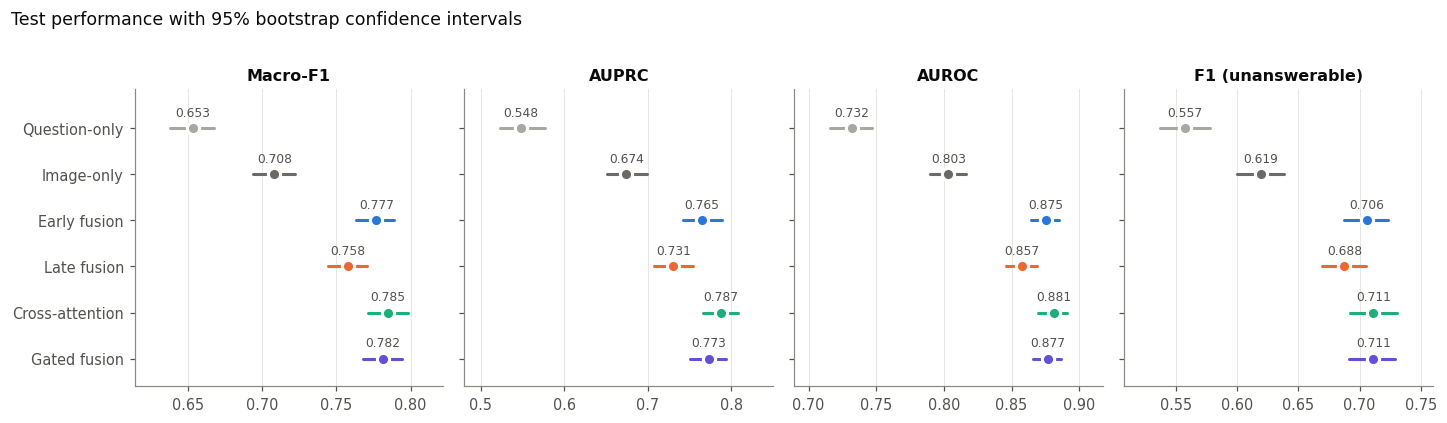

In [ ]:
sys.path.insert(0, "/content")
import importlib
import evaluation as ev
importlib.reload(ev)
ev.set_style()
EFIG = FIG_DIR

ORDER = [DISPLAY[n] for n in ["question_only", "image_only", "early", "late", "cross_attention", "gated"]]
FUSIONS = [n for n in ORDER if n not in ev.UNIMODAL]
y_dev, y_test = Y[IDX["dev"]].astype(int), Y[IDX["test"]].astype(int)


def as_eval(seed):
    pred = {DISPLAY[n]: {sp: RESULTS[seed][n][sp] for sp in ("dev", "test")} for n in RESULTS[seed]}
    thr = {n: round(ev.tune_threshold(pred[n]["dev"], y_dev), 2) for n in pred}       # dev only
    return pred, thr


PRED, THR = as_eval(CONFIG["seed"])
BOOT_IDX = ev.make_boot_idx(len(y_test), CONFIG["n_bootstrap"], CONFIG["seed"])
TABLE, BOOTS = ev.comparison_table(PRED, THR, y_test, ORDER, "test", BOOT_IDX)
TABLE_DEV, _ = ev.comparison_table(PRED, THR, y_dev, ORDER, "dev")
MAIN = ["macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc"]
EXTRA = ["precision_unans", "recall_unans", "specificity", "mcc", "accuracy", "brier", "ece"]
print(f"Test: {len(y_test):,} pairs, {y_test.mean():.1%} unanswerable | dev: {len(y_dev):,} pairs, "
      f"{y_dev.mean():.1%} unanswerable | thresholds (dev-tuned): {THR}")
display(ev.format_table(TABLE, MAIN))
display(ev.format_table(TABLE, EXTRA))
print("Dev minus test (a large drop means the dev-tuned choices do not transfer):")
display((TABLE_DEV[["macro_f1", "auprc", "auroc"]] - TABLE[["macro_f1", "auprc", "auroc"]]).round(3))
TABLE.round(4).to_csv(TAB_DIR / "test_metrics.csv")
ev.format_table(TABLE, MAIN + EXTRA).to_csv(TAB_DIR / "test_metrics_formatted.csv")
ev.plot_metric_intervals(TABLE, ORDER, path=EFIG / "metric_intervals.png")
plt.show()

### 8.1 Are the differences real?

Every pair of models is compared on the same bootstrap resamples and with the exact McNemar test on which test pairs each model gets right; both p-values are Holm-corrected. A difference counts as significant only when its 95% CI excludes zero and the corrected p is below 0.05. The fusion-gain table compares each fusion model with the best single-modality model.

,model_a,model_b,diff,ci_lo,ci_hi,p_bootstrap,p_mcnemar,p_bootstrap_holm,p_mcnemar_holm,significant
0,Question-only,Image-only,-0.0548,-0.0739,-0.0354,0.001,0.0000,0.015,0.0000,True
1,Question-only,Early fusion,-0.1235,-0.1390,-0.1061,0.001,0.0000,0.015,0.0000,True
2,Question-only,Late fusion,-0.1042,-0.1186,-0.0895,0.001,0.0000,0.015,0.0000,True
3,Question-only,Cross-attention,-0.1314,-0.1489,-0.1139,0.001,0.0000,0.015,0.0000,True
4,Question-only,Gated fusion,-0.1281,-0.1451,-0.1107,0.001,0.0000,0.015,0.0000,True
5,Image-only,Early fusion,-0.0687,-0.0819,-0.0539,0.001,0.0000,0.015,0.0000,True
6,Image-only,Late fusion,-0.0494,-0.0621,-0.0367,0.001,0.0000,0.015,0.0000,True
7,Image-only,Cross-attention,-0.0766,-0.0926,-0.0602,0.001,0.0000,0.015,0.0000,True
8,Image-only,Gated fusion,-0.0733,-0.0864,-0.0594,0.001,0.0000,0.015,0.0000,True
9,Early fusion,Late fusion,0.0193,0.0077,0.0304,0.001,0.0000,0.015,0.0002,True


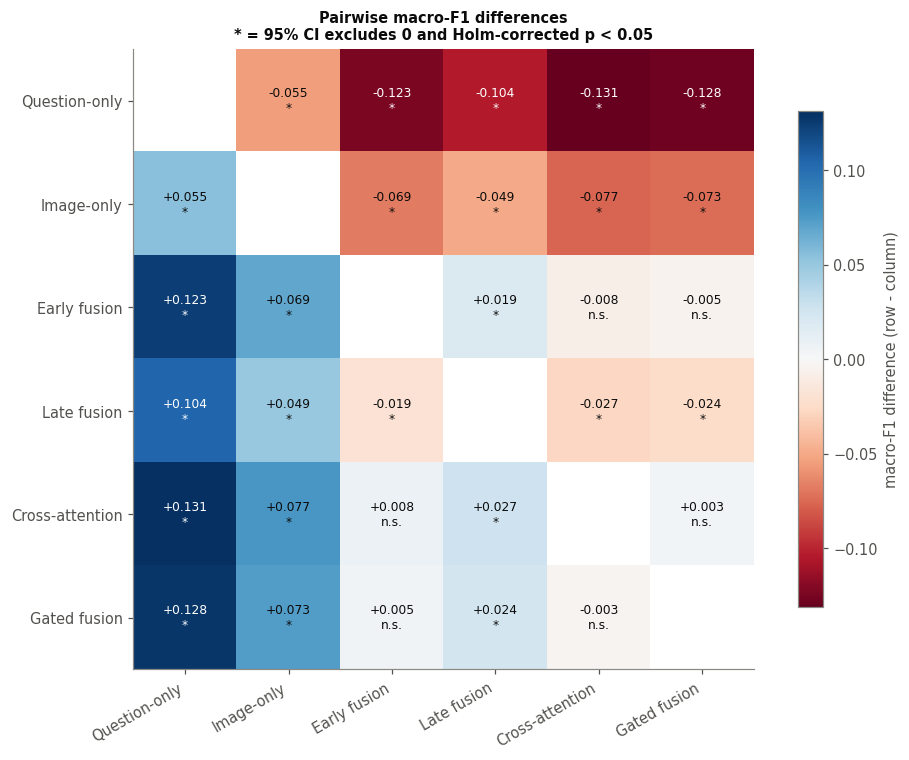

,vs,gain,ci_lo,ci_hi,ci_excludes_zero
fusion,,,,,
Early fusion,Image-only,0.0687,0.0539,0.0819,True
Late fusion,Image-only,0.0494,0.0367,0.0621,True
Cross-attention,Image-only,0.0766,0.0602,0.0926,True
Gated fusion,Image-only,0.0733,0.0594,0.0864,True


In [ ]:
PAIRS = ev.pairwise_significance(PRED, THR, y_test, BOOTS, ORDER)
display(PAIRS.round(4))
PAIRS.round(4).to_csv(TAB_DIR / "pairwise_significance.csv", index=False)
ev.plot_significance_matrix(PAIRS, ORDER, path=EFIG / "significance_matrix.png")
plt.show()
GAINS = ev.fusion_gain(TABLE, BOOTS, fusions=FUSIONS)
display(GAINS.round(4))
GAINS.round(4).to_csv(TAB_DIR / "fusion_gain.csv")

### 8.2 Curves, errors and calibration

ROC shows ranking quality over all thresholds; precision-recall is more informative for the minority class. Confusion matrices show which kind of error each model makes at its dev-tuned threshold. The reliability diagram shows whether a predicted 0.7 really means a 70% chance of being unanswerable; the positive-class weighting is expected to push probabilities upwards.

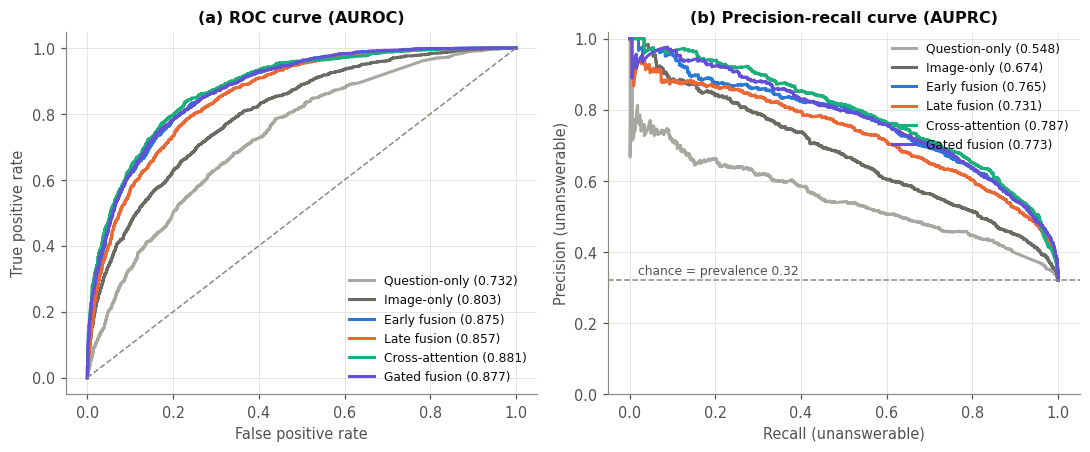

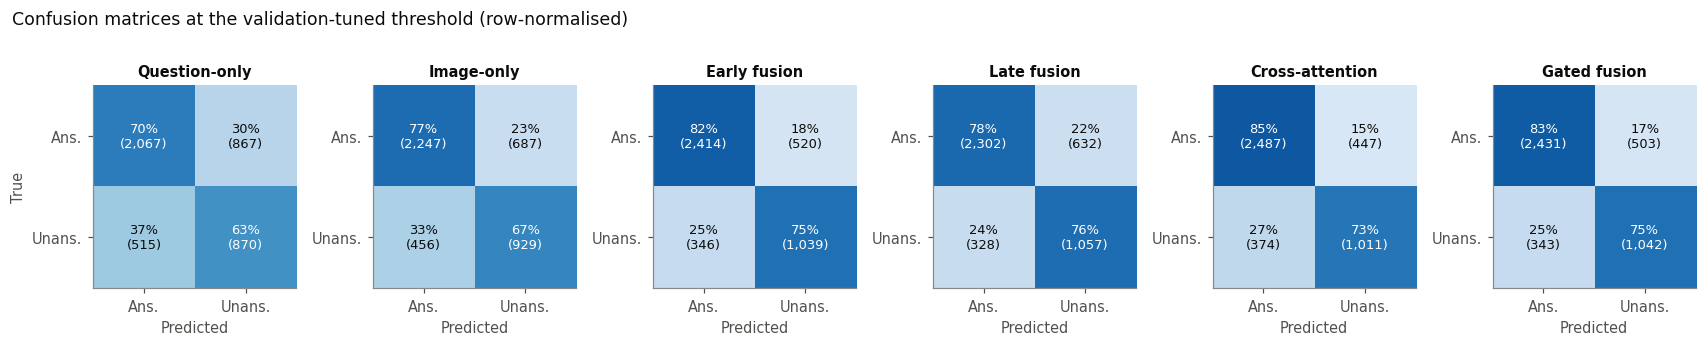

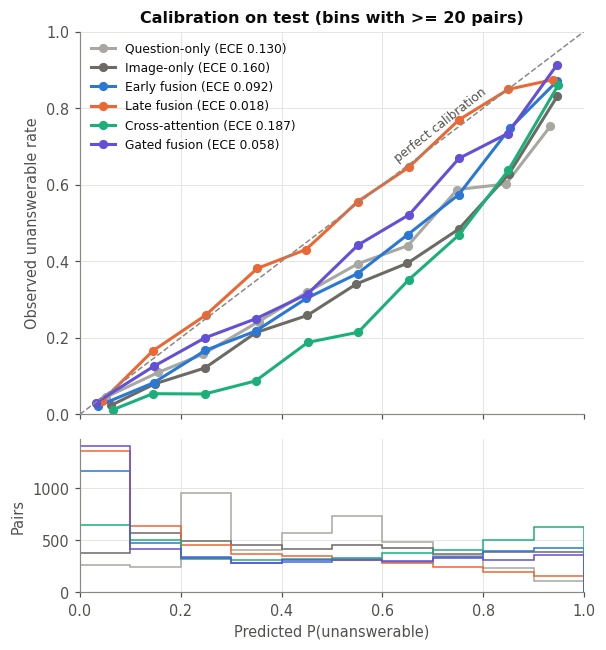

In [ ]:
for f in (ev.plot_roc_pr(PRED, y_test, ORDER, path=EFIG / "roc_pr.png"),
          ev.plot_confusion_grid(PRED, THR, y_test, ORDER, path=EFIG / "confusion_matrices.png"),
          ev.plot_reliability(PRED, y_test, ORDER, path=EFIG / "reliability.png")):
    plt.show()

### 8.3 Robustness across seeds and learning curves

Each model was trained with three seeds; thresholds are re-tuned on each seed's dev predictions. A gap between two models smaller than their seed standard deviation is not a reliable ranking. The learning curves (primary seed) show the train and dev loss per epoch and the epoch kept by early stopping; a widening gap after it is overfitting.

,Macro-F1,AUPRC,AUROC,F1 (unanswerable)
model,,,,
Question-only,0.656 +/- 0.004,0.555 +/- 0.007,0.733 +/- 0.004,0.550 +/- 0.008
Image-only,0.707 +/- 0.006,0.673 +/- 0.002,0.802 +/- 0.001,0.599 +/- 0.028
Early fusion,0.779 +/- 0.001,0.768 +/- 0.006,0.878 +/- 0.003,0.706 +/- 0.004
Late fusion,0.757 +/- 0.001,0.731 +/- 0.003,0.857 +/- 0.004,0.686 +/- 0.005
Cross-attention,0.787 +/- 0.002,0.795 +/- 0.008,0.886 +/- 0.004,0.714 +/- 0.003
Gated fusion,0.777 +/- 0.006,0.772 +/- 0.002,0.877 +/- 0.001,0.696 +/- 0.016


,epochs_run,best_epoch,train_loss_best,dev_loss_best,gap_best,gap_last,dev_auprc_best
model,,,,,,,
Question-only,10,6,0.5245,0.5640,0.0395,0.0974,0.5191
Image-only,12,8,0.4818,0.5554,0.0736,0.1282,0.6324
Early fusion,7,3,0.3499,0.3996,0.0497,0.1772,0.7572
Cross-attention,6,2,0.4817,0.4994,0.0177,0.1845,0.7737
Gated fusion,8,4,0.3393,0.3887,0.0494,0.1219,0.7572


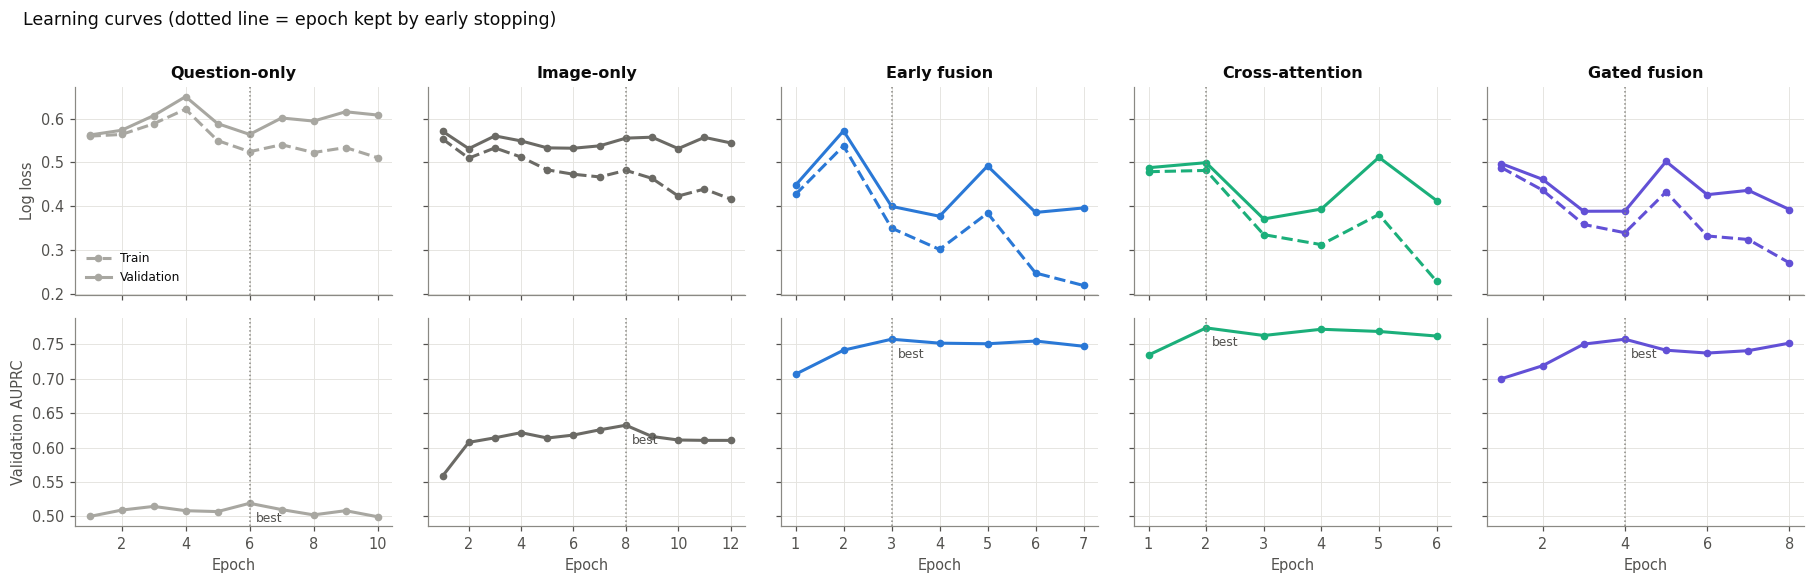

In [ ]:
SEED_TABLES = []
for s in CONFIG["seeds"]:
    p_s, t_s = as_eval(s)
    SEED_TABLES.append(ev.comparison_table(p_s, t_s, y_test, ORDER, "test")[0])
SEED_SUMMARY = ev.seed_summary(SEED_TABLES)
display(ev.format_seed_summary(SEED_SUMMARY, ["macro_f1", "auprc", "auroc", "f1_unans"]))
SEED_SUMMARY.round(4).to_csv(TAB_DIR / "seed_summary.csv")

HIST = {DISPLAY[n]: h for n, h in HISTORY[CONFIG["seed"]].items() if h is not None}
LC = ev.learning_curve_summary(HIST)
display(LC.round(4))
LC.round(4).to_csv(TAB_DIR / "learning_curves_summary.csv")
ev.plot_learning_curves(HIST, ORDER, path=EFIG / "learning_curves.png")
plt.show()

### 8.4 Speed and size

A query is one photo and one question, so latency is measured at batch size 1 on this session's device: the shared encoder stage (decode, letterbox, quality measures, CLIP image and text encoders) plus each model's fusion head. The project budget is 100 ms per query on a T4. Training cost comes from the training logs; late fusion costs both baselines plus the stacker.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Encoder stage per query: median 44.2 ms, p95 74.7 ms on cuda


,macro_f1,auprc,params,train_sec,epochs,peak_vram_gb,head_ms,end_to_end_ms
model,,,,,,,,
Question-only,0.6534,0.5484,132609,3.40,10,0.03,0.3510,44.5245
Image-only,0.7082,0.6743,135189,3.72,12,0.03,0.3873,44.5608
Early fusion,0.7769,0.7652,1059351,2.80,7,0.06,0.4941,44.6677
Late fusion,0.7576,0.7305,267798,7.12,10+12,0.03,0.7382,44.9117
Cross-attention,0.7848,0.7872,2659093,40.08,6,0.82,3.5073,47.6808
Gated fusion,0.7815,0.7730,597251,2.72,8,0.07,0.7569,44.9304


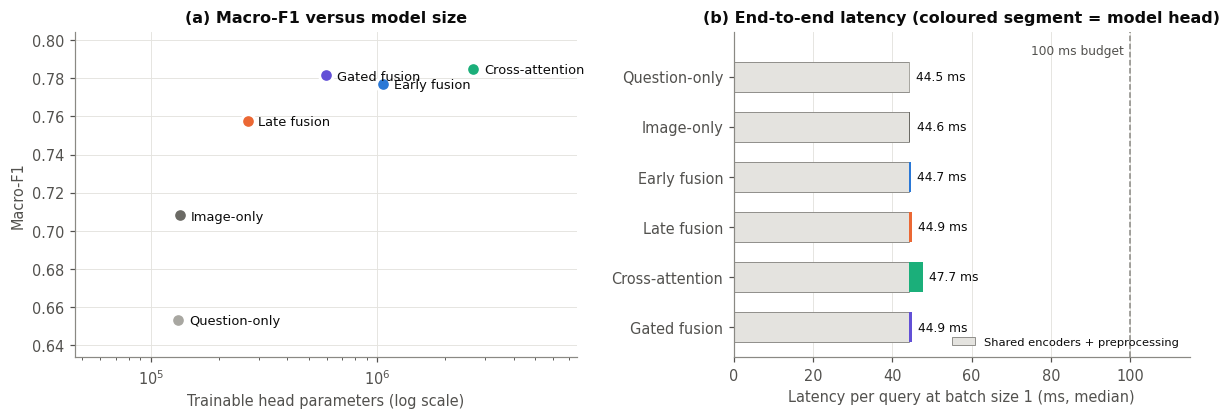

In [ ]:
sync = torch.cuda.synchronize if DEVICE == "cuda" else None
i0 = int(IDX["test"][0])
LAT = {}
for name, model in MODELS.items():
    if model is None:
        continue
    def head(model=model):
        with torch.no_grad():
            return model(batch([i0], model.needs))
    LAT[DISPLAY[name]] = {"head_ms": ev.benchmark(head, sync=sync)["median_ms"]}
LAT["Late fusion"] = {"head_ms": LAT["Question-only"]["head_ms"] + LAT["Image-only"]["head_ms"]}

clip_model, tokenizer = load_clip(CONFIG["clip_model"])
one = PhotoSet([meta["path"].iloc[i0]])
question = [meta["question"].iloc[i0]]

def encode_one():
    x, q, _ = one[0]                                   # decode, EXIF, quality measures, letterbox
    with torch.no_grad(), autocast():
        out = clip_model.vision_model(pixel_values=x.unsqueeze(0).to(DEVICE))
        clip_model.visual_projection(out.pooler_output)
        enc = tokenizer(question, padding="max_length", truncation=True, max_length=CONFIG["max_q_tokens"],
                        return_tensors="pt").to(DEVICE)
        t = clip_model.text_model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
        clip_model.text_projection(t.pooler_output)

ENC = ev.benchmark(encode_one, repeats=30, sync=sync)
del clip_model
for n in LAT:
    LAT[n]["end_to_end_ms"] = ENC["median_ms"] + LAT[n]["head_ms"]
print(f"Encoder stage per query: median {ENC['median_ms']:.1f} ms, p95 {ENC['p95_ms']:.1f} ms on {DEVICE}")

COST = {DISPLAY[n]: c for n, c in COSTS[CONFIG["seed"]].items()}
EFF = ev.efficiency_table(TABLE, COST, LAT, composite={"Late fusion": ["Question-only", "Image-only"]})
display(EFF.round(4))
EFF.round(4).to_csv(TAB_DIR / "efficiency.csv")
ev.plot_efficiency(EFF, ORDER, budget_ms=CONFIG["latency_budget_ms"], path=EFIG / "efficiency.png")
plt.show()

### 8.5 What each fusion model relies on

**Modality ablation.** At test time the question inputs (embedding, tokens, cosine) or the photo inputs (embedding, regions, quality measures, cosine) are replaced by their training means, so the model receives no information from that modality while input shapes stay the same. The drop in AUPRC measures reliance on each modality. The question padding mask is kept, so question length still leaks through for cross-attention.

**Complementarity.** Test pairs are grouped by which single-modality model is right. Perfect fusion would be right in every "only one right" group; the gap to the single-modality oracle is complementary signal that fusion does not yet use.

auprc  macro_f1  auprc_drop  macro_f1_drop
model           condition                                                             
Early fusion    full                       0.7652    0.7769      0.0000         0.0000
                question replaced by mean  0.6448    0.6973      0.1204         0.0796
                photo replaced by mean     0.5207    0.5905      0.2445         0.1864
Cross-attention full                       0.7872    0.7848      0.0000         0.0000
                question replaced by mean  0.6058    0.6601      0.1814         0.1247
                photo replaced by mean     0.5323    0.6364      0.2549         0.1484
Gated fusion    full                       0.7730    0.7815      0.0000         0.0000
                question replaced by mean  0.6502    0.7005      0.1228         0.0810
                photo replaced by mean     0.5374    0.6327      0.2355         0.1488

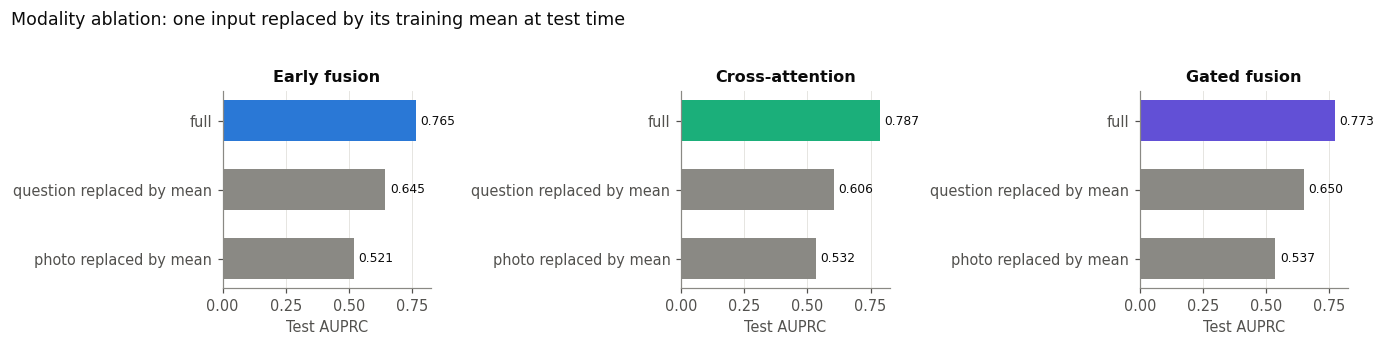

,share,n,Early fusion,Late fusion,Cross-attention,Gated fusion
group,,,,,,
Both right,0.508,2193,0.969,1.000,0.947,0.976
Only question right,0.172,744,0.638,0.608,0.704,0.638
Only image right,0.228,983,0.780,0.727,0.765,0.788
Both wrong,0.092,399,0.216,0.000,0.363,0.208


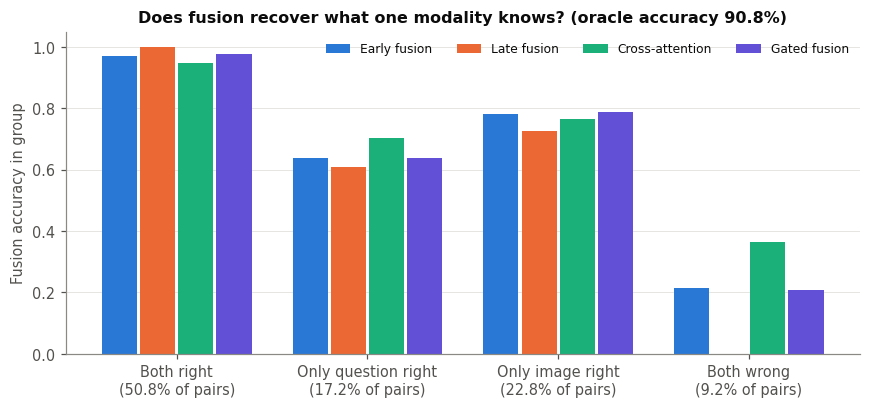

Share of test pairs by number of models wrong:


,proportion
n_models_wrong,
0,0.470
1,0.231
2,0.072
3,0.059
4,0.051
5,0.065
6,0.053


In [ ]:
def train_mean(k, bs=2048):
    total, count = 0, 0
    for i in range(0, len(IDX["train"]), bs):
        idx = torch.as_tensor(IDX["train"][i:i + bs])
        x = X[k][idx].float()
        if k == "q_tok":                                   # mean over real (unpadded) tokens only
            m = X["q_mask"][idx].float().unsqueeze(-1)
            total, count = total + (x * m).sum((0, 1)), count + m.sum()
        else:
            total, count = total + x.sum(0), count + len(idx)
    mean = total / count
    return mean.expand(*X[k].shape[1:]) if k == "q_tok" else mean
Q_KEYS, V_KEYS = ("q_emb", "q_tok", "cos"), ("v_emb", "v_tok", "quality", "cos")
MEANS = {k: train_mean(k) for k in set(Q_KEYS + V_KEYS)}

ABL_SCORES = {}
for name in ("early", "cross_attention", "gated"):
    model = MODELS.get(name)
    if model is None:
        continue
    ABL_SCORES[DISPLAY[name]] = {
        "full": PRED[DISPLAY[name]]["test"],
        "question replaced by mean": predict(model, IDX["test"], {k: MEANS[k] for k in Q_KEYS})[0],
        "photo replaced by mean": predict(model, IDX["test"], {k: MEANS[k] for k in V_KEYS})[0]}
ABL = ev.ablation_table(ABL_SCORES, y_test, THR)
display(ABL.round(4))
ABL.round(4).to_csv(TAB_DIR / "modality_ablation.csv")
ev.plot_ablation(ABL, path=EFIG / "modality_ablation.png")
plt.show()

test_meta = meta.iloc[IDX["test"]][["image", "question", "path", "q_words", "q_category", "frequent_question",
                                    "unans_votes", "consensus", "clip_cosine", "sharpness", "brightness"]]
PP = ev.per_pair_predictions(test_meta, PRED, THR, y_test, ORDER)
if RESULTS[CONFIG["seed"]]["gated"].get("gate_test") is not None:
    PP["gate_q"] = RESULTS[CONFIG["seed"]]["gated"]["gate_test"]
PP.drop(columns=["path"]).to_csv(TAB_DIR / "per_pair_predictions_test.csv", index=False)
COMP = ev.complementarity(PP, FUSIONS)
display(COMP.round(3))
COMP.round(4).to_csv(TAB_DIR / "complementarity.csv")
ev.plot_complementarity(COMP, FUSIONS, path=EFIG / "complementarity.png")
plt.show()
print("Share of test pairs by number of models wrong:")
display(PP["n_models_wrong"].value_counts(normalize=True).sort_index().round(3))

### 8.6 Failure cases

The error profile compares the best model's false negatives (unanswerable pairs it called answerable) and false positives with its correct predictions on descriptors it never saw as labels: question length and type, crowd votes, CLIP similarity, sharpness, brightness and (for the gated model) the gate value. The galleries show its most confident mistakes; read them for patterns such as blur, text on packaging, framing and ambiguous labels (pairs where only 3-7 of 10 workers agreed).

,n,q_words,frequent_question,reading_question,unans_votes,consensus,clip_cosine,sharpness,brightness,gate_q
outcome,,,,,,,,,,
TP,1011,8.452,0.155,0.255,7.817,0.782,0.244,3.103,0.425,0.540
FN,374,7.861,0.174,0.190,6.920,0.692,0.243,3.898,0.425,0.543
TN,2487,6.212,0.328,0.099,0.871,0.491,0.247,4.196,0.429,0.546
FP,447,9.016,0.114,0.199,2.300,0.471,0.253,3.766,0.423,0.542


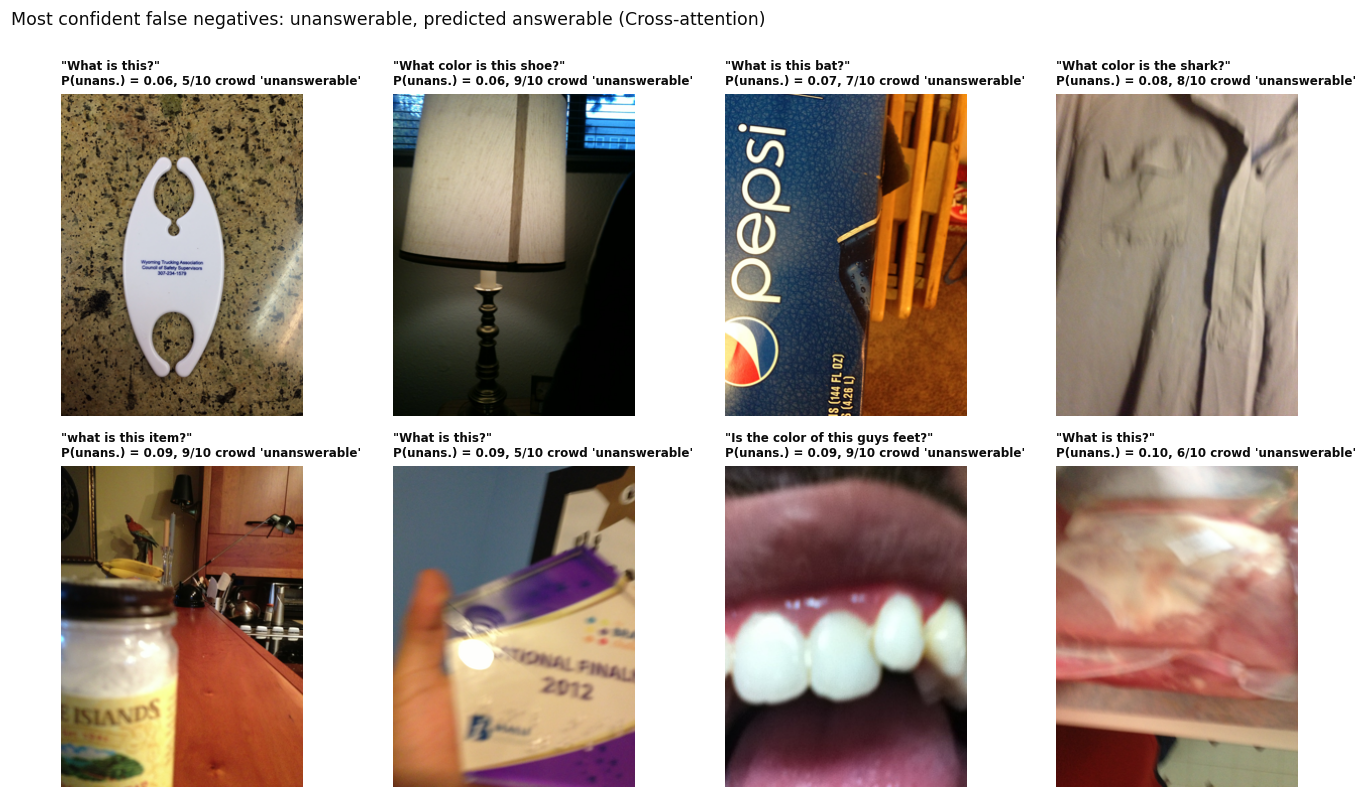

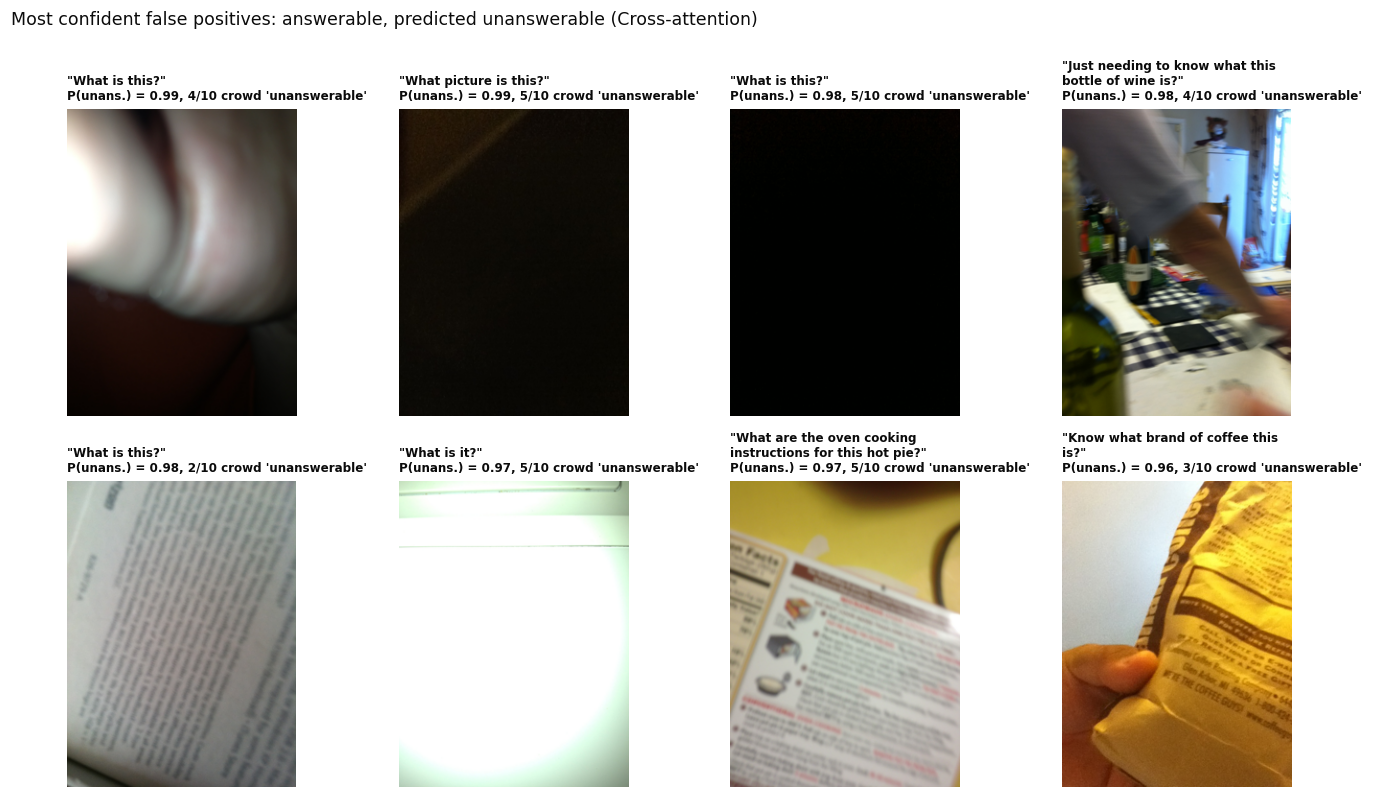

Cross-attention: error rate 38.3% on ambiguous pairs (3-7 of 10 votes, 27.6% of test) vs 11.6% on the rest


In [ ]:
BEST = TABLE["macro_f1"].idxmax()
PP["reading_question"] = (PP["q_category"] == "reading text").astype(int)
PROFILE_COLS = [c for c in ["q_words", "frequent_question", "reading_question", "unans_votes", "consensus",
                            "clip_cosine", "sharpness", "brightness", "gate_q"] if c in PP]
PROFILE = ev.describe_outcomes(PP, BEST, PROFILE_COLS)
display(PROFILE.round(3))
PROFILE.round(4).to_csv(TAB_DIR / "error_profile.csv")

FN, FP = ev.top_errors(PP, BEST, "FN", k=8), ev.top_errors(PP, BEST, "FP", k=8)
ev.plot_failure_gallery(FN, BEST, "Most confident false negatives: unanswerable, predicted answerable",
                        path=EFIG / "failures_false_negatives.png")
plt.show()
ev.plot_failure_gallery(FP, BEST, "Most confident false positives: answerable, predicted unanswerable",
                        path=EFIG / "failures_false_positives.png")
plt.show()
ERRORS = pd.concat([FN.assign(kind="FN"), FP.assign(kind="FP")]).drop(columns=["path"])
ERRORS.to_csv(TAB_DIR / "top_errors.csv", index=False)
ambiguous = PP["unans_votes"].between(3, 7)
wrong = ~PP[f"ok::{BEST}"]
print(f"{BEST}: error rate {wrong[ambiguous].mean():.1%} on ambiguous pairs (3-7 of 10 votes, "
      f"{ambiguous.mean():.1%} of test) vs {wrong[~ambiguous].mean():.1%} on the rest")

## 9. Subgroups, threshold trade-off and deployment

**Subgroup performance.** The best model's recall on unanswerable pairs (how many it catches) and false-positive rate (answerable questions wrongly flagged) are compared across groups that matter for blind users: photo sharpness and brightness (quartiles of the training distribution), question category and question length, and whether the question is one of the 20 most frequent. Intervals are Wilson 95% intervals (Wilson 1927); groups with fewer than 20 unanswerable pairs are shown but not used to rank gaps, because their recall is too uncertain. A large gap means the system serves some photos or questions much worse than others.

**Threshold trade-off.** A false negative tells a user their question can be answered when it cannot (they wait for an answer that will not come); a false positive asks them to retake a photo unnecessarily. The dev-tuned macro-F1 threshold balances both; for deployment a threshold reaching the target recall on dev is also reported, with its cost in false positives on test.

,group,value,n,n_unans,unanswerable_rate,recall_unans,recall_lo,recall_hi,fpr,fpr_lo,fpr_hi,auprc
0,sharpness_group,Q1 blurriest,1041,549,0.527,0.845,0.813,0.873,0.224,0.189,0.262,0.896
1,sharpness_group,Q2,1085,348,0.321,0.707,0.657,0.752,0.171,0.146,0.200,0.746
2,sharpness_group,Q3,1069,260,0.243,0.635,0.575,0.691,0.145,0.122,0.171,0.625
3,sharpness_group,Q4 sharpest,1124,228,0.203,0.596,0.532,0.658,0.105,0.087,0.127,0.658
4,brightness_group,dark (bottom 25%),1182,421,0.356,0.736,0.692,0.776,0.176,0.151,0.205,0.783
5,brightness_group,middle,2177,640,0.294,0.725,0.689,0.758,0.136,0.120,0.154,0.778
6,brightness_group,bright (top 25%),960,324,0.338,0.731,0.681,0.777,0.164,0.137,0.194,0.814
7,q_category,colour,364,19,0.052,0.105,0.029,0.314,0.012,0.005,0.029,0.208
8,q_category,description,157,43,0.274,0.651,0.502,0.776,0.140,0.088,0.216,0.692
9,q_category,identification,1332,292,0.219,0.688,0.633,0.739,0.072,0.058,0.089,0.782


,recall_gap,fpr_gap
group,,
brightness_group,0.011,0.040
frequency_group,0.027,0.133
length_group,0.074,0.227
q_category,0.133,0.194
sharpness_group,0.249,0.119


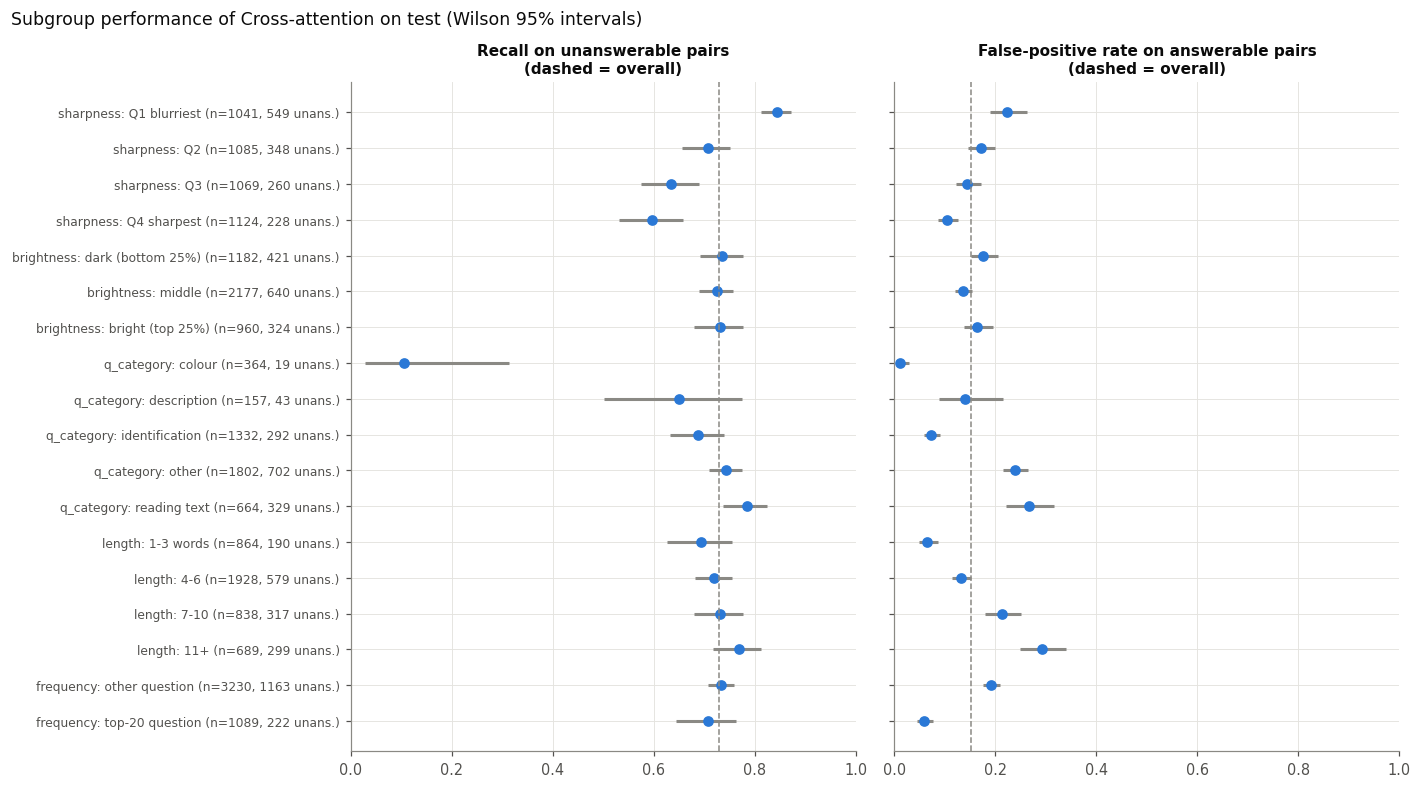

In [ ]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (c - h, c + h)


def subgroup_table(df, model, col):
    rows = []
    for g, d in df.groupby(col, observed=True):
        pos, neg = d[d.y == 1], d[d.y == 0]
        tp, fp = int(pos[f"pred::{model}"].sum()), int(neg[f"pred::{model}"].sum())
        r_lo, r_hi = wilson(tp, len(pos))
        f_lo, f_hi = wilson(fp, len(neg))
        rows.append({"group": col, "value": str(g), "n": len(d), "n_unans": len(pos), "unanswerable_rate": d.y.mean(),
                     "recall_unans": tp / len(pos) if len(pos) else np.nan, "recall_lo": r_lo, "recall_hi": r_hi,
                     "fpr": fp / len(neg) if len(neg) else np.nan, "fpr_lo": f_lo, "fpr_hi": f_hi,
                     "auprc": average_precision_score(d.y, d[f"p::{model}"]) if 0 < d.y.sum() < len(d) else np.nan})
    return pd.DataFrame(rows)


train_q = meta.iloc[IDX["train"]]
PP["sharpness_group"] = pd.cut(PP["sharpness"], [-np.inf, *train_q["sharpness"].quantile([0.25, 0.5, 0.75]), np.inf],
                               labels=["Q1 blurriest", "Q2", "Q3", "Q4 sharpest"])
PP["brightness_group"] = pd.cut(PP["brightness"], [-np.inf, *train_q["brightness"].quantile([0.25, 0.75]), np.inf],
                                labels=["dark (bottom 25%)", "middle", "bright (top 25%)"])
PP["length_group"] = pd.cut(PP["q_words"], [0, 3, 6, 10, np.inf], labels=["1-3 words", "4-6", "7-10", "11+"])
PP["frequency_group"] = PP["frequent_question"].map({1: "top-20 question", 0: "other question"})
GROUPS = ["sharpness_group", "brightness_group", "q_category", "length_group", "frequency_group"]
SUB = pd.concat([subgroup_table(PP, BEST, g) for g in GROUPS], ignore_index=True)
display(SUB.round(3))
SUB.round(4).to_csv(TAB_DIR / "subgroups.csv", index=False)
MIN_UNANS = 20                       # recall in smaller groups is too uncertain to rank
SUPPORTED = SUB[SUB["n_unans"] >= MIN_UNANS]
GAPS = SUPPORTED.groupby("group").agg(recall_gap=("recall_unans", lambda s: s.max() - s.min()),
                                fpr_gap=("fpr", lambda s: s.max() - s.min())).round(3)
display(GAPS)

fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(SUB) + 1.5), sharey=True)
ypos = np.arange(len(SUB))[::-1]
for ax, (m, lo, hi, title) in zip(axes, (("recall_unans", "recall_lo", "recall_hi", "Recall on unanswerable pairs"),
                                         ("fpr", "fpr_lo", "fpr_hi", "False-positive rate on answerable pairs"))):
    ax.hlines(ypos, SUB[lo], SUB[hi], color="#8a8984", lw=2)
    ax.plot(SUB[m], ypos, "o", color="#2a78d6", ms=6)
    overall = (PP.loc[PP.y == 1, f"pred::{BEST}"].mean() if m == "recall_unans"
               else PP.loc[PP.y == 0, f"pred::{BEST}"].mean())
    ax.axvline(overall, ls="--", color="#8a8984", lw=1)
    ax.set_title(f"{title}\n(dashed = overall)", fontsize=10)
    ax.set_xlim(0, 1)
axes[0].set_yticks(ypos, [f"{g.replace('_group', '')}: {v} (n={n}, {k} unans.)"
                         for g, v, n, k in zip(SUB.group, SUB.value, SUB.n, SUB.n_unans)], fontsize=8)
fig.suptitle(f"Subgroup performance of {BEST} on test (Wilson 95% intervals)", x=0.01, ha="left")
fig.tight_layout()
savefig(fig, "subgroups")

,operating point,threshold,test_recall_unans,test_fpr,flags_per_100_queries
0,macro-F1 (dev-tuned),0.72,0.730,0.152,33.758
1,recall >= 90% on dev,0.47,0.914,0.363,53.994


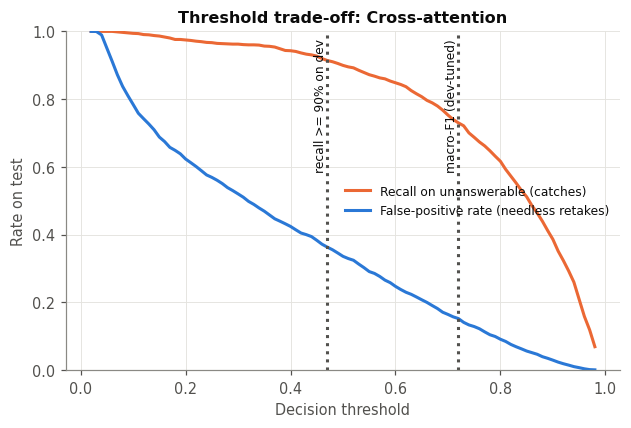

In [ ]:
p_dev, p_test = PRED[BEST]["dev"], PRED[BEST]["test"]
grid = np.linspace(0.02, 0.98, 97)
def rates(p, y, t):
    yhat = p >= t
    return (yhat[y == 1]).mean(), (yhat[y == 0]).mean()
curve = pd.DataFrame([(t, *rates(p_test, y_test, t)) for t in grid], columns=["threshold", "recall", "fpr"])
dev_recall = np.array([rates(p_dev, y_dev, t)[0] for t in grid])
ok = grid[dev_recall >= CONFIG["target_recall_unanswerable"]]
t_recall = float(ok.max()) if len(ok) else float(grid[0])
OPS = pd.DataFrame([{"operating point": name, "threshold": t,
                     **dict(zip(["test_recall_unans", "test_fpr"], rates(p_test, y_test, t))),
                     "flags_per_100_queries": 100 * (p_test >= t).mean()}
                    for name, t in (("macro-F1 (dev-tuned)", THR[BEST]),
                                    (f"recall >= {CONFIG['target_recall_unanswerable']:.0%} on dev", t_recall))])
display(OPS.round(3))
OPS.round(4).to_csv(TAB_DIR / "operating_points.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curve.threshold, curve.recall, color="#eb6834", label="Recall on unanswerable (catches)")
ax.plot(curve.threshold, curve.fpr, color="#2a78d6", label="False-positive rate (needless retakes)")
for _, r in OPS.iterrows():
    ax.axvline(r.threshold, ls=":", color="#52514e")
    ax.annotate(r["operating point"], (r.threshold, 0.98), rotation=90, va="top", ha="right", fontsize=8)
ax.set(xlabel="Decision threshold", ylabel="Rate on test", title=f"Threshold trade-off: {BEST}", ylim=(0, 1))
ax.legend(fontsize=8, loc="center right")
savefig(fig, "threshold_tradeoff")

## 10. Findings and reproducibility record

The findings are generated from the tables above, so every number can be traced to a file in `tables/`. The record below lists the data, splits, timings and software versions needed to reproduce the run.

In [ ]:
FINDINGS = ev.findings(TABLE, PAIRS, GAINS, EFF, COMP, LC)
worst = SUPPORTED.loc[SUPPORTED["recall_unans"].idxmin()]
FINDINGS.append(f"Lowest recall on unanswerable pairs for {BEST}: {worst['group'].replace('_group', '')} = "
                f"{worst['value']} ({worst['recall_unans']:.2f}, {worst['n_unans']} unanswerable pairs); largest recall gap within a "
                f"grouping: {GAPS['recall_gap'].max():.2f} ({GAPS['recall_gap'].idxmax().replace('_group', '')}); groups with fewer "
                f"than {MIN_UNANS} unanswerable pairs are not ranked.")
FINDINGS.append(f"Seed spread of macro-F1 is at most {SEED_SUMMARY['macro_f1_std'].max():.3f}; differences between "
                "fusion models smaller than this are not a reliable ranking.")
print("\n".join("- " + f for f in FINDINGS))

RECORD = {"split_scheme": SPLIT_SCHEME, "splits": split_table.to_dict(), "config": CONFIG, "config_hash": CONFIG_HASH,
          "feature_fingerprint": FINGERPRINT, "text_stats": TEXT_STATS, "extraction": FEAS,
          "training_minutes": TRAIN_MINUTES, "environment": ENV, "late_fusion_weights": LATE_WEIGHTS,
          "thresholds": THR, "best_model": BEST, "findings": FINDINGS,
          "downloads": json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else None}
try:
    import transformers, sklearn, scipy
    ENV.update(transformers=transformers.__version__, sklearn=sklearn.__version__, scipy=scipy.__version__)
except ImportError:
    pass
ev.save_json(RECORD, OUT / "run_record.json")
print(f"\nTables: {TAB_DIR}\nFigures: {FIG_DIR}\nRecord: {OUT / 'run_record.json'}")

- Best macro-F1: Cross-attention at 0.785 (95% CI 0.771 to 0.798), AUPRC 0.787, AUROC 0.881.
- Early fusion vs Image-only: macro-F1 +0.069 (95% CI +0.054 to +0.082); the CI excludes zero.
- Late fusion vs Image-only: macro-F1 +0.049 (95% CI +0.037 to +0.062); the CI excludes zero.
- Cross-attention vs Image-only: macro-F1 +0.077 (95% CI +0.060 to +0.093); the CI excludes zero.
- Gated fusion vs Image-only: macro-F1 +0.073 (95% CI +0.059 to +0.086); the CI excludes zero.
- Early fusion and Cross-attention are not significantly different (diff -0.008, CI -0.019 to +0.004, Holm p = 0.546).
- Early fusion and Gated fusion are not significantly different (diff -0.005, CI -0.015 to +0.004, Holm p = 0.664).
- Cross-attention and Gated fusion are not significantly different (diff +0.003, CI -0.008 to +0.015, Holm p = 0.664).
- Calibration: ECE ranges from 0.018 (Late fusion) to 0.187 (Cross-attention).
- Size: Cross-attention has 9.9x the parameters of Late fusion and trains 5.6x longer, for a

## References

Arevalo, J, Solorio, T, Montes-y-Gomez, M & Gonzalez, FA 2017, 'Gated multimodal units for information fusion', in *5th international conference on learning representations (ICLR 2017), workshop track*, Toulon, France.

Baltrusaitis, T, Ahuja, C & Morency, L-P 2019, 'Multimodal machine learning: a survey and taxonomy', *IEEE Transactions on Pattern Analysis and Machine Intelligence*, vol. 41, no. 2, pp. 423-443.

Brier, GW 1950, 'Verification of forecasts expressed in terms of probability', *Monthly Weather Review*, vol. 78, no. 1, pp. 1-3.

Dietterich, TG 1998, 'Approximate statistical tests for comparing supervised classification learning algorithms', *Neural Computation*, vol. 10, no. 7, pp. 1895-1923.

Efron, B & Tibshirani, RJ 1993, *An introduction to the bootstrap*, Chapman & Hall, New York.

Guo, C, Pleiss, G, Sun, Y & Weinberger, KQ 2017, 'On calibration of modern neural networks', in *Proceedings of the 34th international conference on machine learning (ICML 2017)*, PMLR, vol. 70, pp. 1321-1330.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Hasler, D & Suesstrunk, SE 2003, 'Measuring colorfulness in natural images', in *Human vision and electronic imaging VIII*, Proceedings of SPIE, vol. 5007, pp. 87-95.

Holm, S 1979, 'A simple sequentially rejective multiple test procedure', *Scandinavian Journal of Statistics*, vol. 6, no. 2, pp. 65-70.

Loshchilov, I & Hutter, F 2019, 'Decoupled weight decay regularization', in *7th international conference on learning representations (ICLR 2019)*, New Orleans, USA.

McNemar, Q 1947, 'Note on the sampling error of the difference between correlated proportions or percentages', *Psychometrika*, vol. 12, no. 2, pp. 153-157.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, IEEE, Barcelona, Spain, vol. 3, pp. 314-317.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

Saito, T & Rehmsmeier, M 2015, 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, vol. 10, no. 3, article no. e0118432.

Tsai, Y-HH, Bai, S, Liang, PP, Kolter, JZ, Morency, L-P & Salakhutdinov, R 2019, 'Multimodal transformer for unaligned multimodal language sequences', in *Proceedings of the 57th annual meeting of the Association for Computational Linguistics*, Florence, Italy, pp. 6558-6569.

Vaswani, A, Shazeer, N, Parmar, N, Uszkoreit, J, Jones, L, Gomez, AN, Kaiser, L & Polosukhin, I 2017, 'Attention is all you need', in *Advances in neural information processing systems 30 (NeurIPS 2017)*, Long Beach, USA, pp. 5998-6008.

Wilson, EB 1927, 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, vol. 22, no. 158, pp. 209-212.

Wolf, T, Debut, L, Sanh, V, Chaumond, J, Delangue, C, Moi, A, Cistac, P, Rault, T, Louf, R, Funtowicz, M, Davison, J, Shleifer, S, von Platen, P, Ma, C, Jernite, Y, Plu, J, Xu, C, Le Scao, T, Gugger, S, Drame, M, Lhoest, Q & Rush, AM 2020, 'Transformers: state-of-the-art natural language processing', in *Proceedings of the 2020 conference on empirical methods in natural language processing: system demonstrations*, pp. 38-45.